# Billboard: Top 10 or Not?

BA780 Team Assignment — Team A05

Team members: Muhammad Azaan, Omar Tawfik, Caitlin Jeng, Xiaoquan Dai

---

#### How this notebook is organised

| Section | What you will find |
|---|---|
| Executive summary | The answer in one paragraph, plus a table of the findings |
| 1. Problem definition | The target, the songs we study, and the rule that every predictor must be known at debut |
| 2. Data description | The three data sources and how they join |
| 3. Data cleaning | Step-by-step cleaning from the raw files (skip it if you only want the findings) |
| 4. Exploratory questions | Data checks (4.0), then 15 questions in five themes, each with a test and a chart |
| 5. Conclusion | Ranked insights, risks and limitations, next steps |
| 6-7. References and AI use | Sources, software and how we used AI |

Every question in Section 4 has the same five parts: the research question, the data analysis, the chart, the
finding with its numbers, and an interpretation that avoids claiming cause and effect. Every chart has a headline
that states its result.

#### Research question

Among songs that reached the Billboard Hot 100 between January 2018 and September 2026,
what distinguishes those that climbed into the Top 10 from those that peaked lower?

#### Why this matters

These findings show that a song’s commercial success is more closely associated with artist history, release strategy, and genre than with measurable lyrical features. This matters because it helps artists, labels, and marketers focus on the factors that are more closely associated with chart performance. It also highlights the importance of careful statistical testing, since apparent patterns can disappear once confounding effects and data leakage are addressed.


#### Data sources, access and licensing

| Source | What we used | Access URL | Licence |
|---|---|---|---|
| Billboard Hot 100 weekly archive (mhollingshead) | every weekly chart, 1958-2026 | https://github.com/mhollingshead/billboard-hot-100 | No licence declared by the repository. The underlying chart is Billboard's copyrighted compilation |
| LRCLIB | song lyrics | https://lrclib.net/docs | No licence stated on the public docs page. Lyrics remain the rights holders' property |
| MusicBrainz | release dates, release type, genres, artist metadata | https://musicbrainz.org/doc/MusicBrainz_API | Core data CC0 / public domain; some supplementary data CC-BY-NC-SA |

We checked each source rather than assuming. Only MusicBrainz's licence is explicit.
The other two are used here for non-commercial academic analysis only, and neither
the raw lyrics nor the chart archive should be redistributed from this repository.
This is revisited in *Risks and limitations*.

#### Reproducibility

Runs top to bottom with Restart & Run All, using relative paths only. Section 3 rebuilds the
cleaned dataset from the raw files in `data/raw/` (`all.json`, `lyrics.csv`, `mb_songs.csv`,
`mb_artists.csv`) and checks it against `data/clean/songs_analysis.csv`, which the analysis in
Section 4 reads. In Colab, the first cell asks you to upload any file that is missing.
It makes no API calls: the lyrics and MusicBrainz files are the saved results of our
earlier API requests. NumPy is seeded at 42.

In [1]:
# Run me first: make sure the raw files and the analysis file are in place.
import os

NEEDED = {
    "all.json":           "data/raw/all.json",            # Billboard weekly archive
    "lyrics.csv":         "data/raw/lyrics.csv",          # LRCLIB results
    "mb_songs.csv":       "data/raw/mb_songs.csv",        # MusicBrainz recordings
    "mb_artists.csv":     "data/raw/mb_artists.csv",      # MusicBrainz artists
    "songs_analysis.csv": "data/clean/songs_analysis.csv",  # cleaned file used in Section 4
}
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

missing = [name for name, path in NEEDED.items() if not os.path.exists(path)]
if missing:
    try:
        from google.colab import files       # Colab: upload the missing files in one go
        print("Please upload:", ", ".join(missing))
        files.upload()
        for name in missing:
            os.replace(name, NEEDED[name])
    except ImportError:                      # local Jupyter: the files must already be there
        raise FileNotFoundError(f"Place these files (from the team Drive) at: {[NEEDED[m] for m in missing]}")
for name, path in NEEDED.items():
    print(f"ready: {path}")


ready: data/raw/all.json
ready: data/raw/lyrics.csv
ready: data/raw/mb_songs.csv
ready: data/raw/mb_artists.csv
ready: data/clean/songs_analysis.csv


In [2]:
# Setup: load the libraries, set the chart style and two chart helpers, then read the dataset.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import zipfile
import missingno as msno

np.random.seed(42)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 60)

# Colours (slate and clay): slate marks the point of each chart, stone is context, clay is a second group.
FOCUS, SECOND, CONTEXT, PALE = "#356C93", "#E0814D", "#DCD5C9", "#ECE7DE"
FOCUS_LIGHT, FOCUS_PALE = "#8DB0CA", "#C8D9E6"            # lighter slate for box plots
GOLD, CORAL, SEAFOAM = "#EDB548", "#DB6440", "#7DB5AA"    # extra tones for the genre-mix chart
REF, BACKGROUND, TEXT, MUTED = "#A39E95", "#F8F6F1", "#2B3036", "#6A7078"
RATE_LABEL = "Share of songs reaching the Top 10 (%)"
SOURCE = "Source: Billboard Hot 100 archive and MusicBrainz · songs that debuted 2018–2024"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10.5, "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
                     "savefig.facecolor": BACKGROUND, "text.color": TEXT, "axes.labelcolor": MUTED,
                     "axes.edgecolor": "#BDB6AA", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": "#E7E2D9",
                     "legend.frameon": False})
GENRE_NAMES = {"pop": "Pop", "hip-hop/rap": "Hip-hop/rap", "R&B": "R&B", "country": "Country", "Latin": "Latin",
               "rock/alternative": "Rock/alternative", "dance/electronic": "Dance/electronic",
               "mixed": "Mixed (tied genres)", "other": "Other"}

def bars(ax, labels, groups, horizontal=False, bar_labels=None):
    """Labelled bars. groups = [(legend name, values, colour), ...]; two or three groups sit side by side."""
    x = np.arange(len(labels))
    width = 0.6 if len(groups) == 1 else 0.78 / len(groups)
    for k, (name, values, colour) in enumerate(groups):
        pos = x + (k - (len(groups) - 1) / 2) * width
        if horizontal:
            drawn = ax.barh(pos, values, height=width, color=colour, label=name)
        else:
            drawn = ax.bar(pos, values, width=width, color=colour, label=name)
        ax.bar_label(drawn, labels=bar_labels, fmt="%.1f%%", padding=3, fontsize=9.5 if len(groups) < 3 else 8.5,
                     bbox=dict(facecolor=BACKGROUND, edgecolor="none", pad=1))
    if horizontal:
        ax.set_yticks(x, labels)
        ax.invert_yaxis()                       # first label at the top
        ax.tick_params(axis="y", length=0)
    else:
        ax.set_xticks(x, labels)
    ax.grid(axis="x" if horizontal else "y")
    if len(groups) > 1:
        ax.legend()

def finish(fig, ax, number, headline, subtitle, source=SOURCE, extra_space=0):
    """Lay the chart out, put 'CHART n', a headline and a subtitle above ax and the source below, then show it.
    extra_space lifts the titles when the panels already have their own titles."""
    fig.tight_layout(rect=(0, 24 / (fig.get_figheight() * 72), 1, 1))
    y = 12 + extra_space
    for text, style in [(subtitle, dict(fontsize=10, color=MUTED)), (headline, dict(fontsize=13.5, fontweight="bold")),
                        (f"CHART {number}", dict(fontsize=8.5, fontweight="bold", color=MUTED))]:
        ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, y), textcoords="offset points", va="bottom", **style)
        y += 14 * (text.count("\n") + 1) + 6 if text == subtitle else 24
    fig.text(min(a.get_position().x0 for a in fig.axes), 0.004, source, fontsize=8, color=MUTED)
    plt.show()

DATA = "data/clean/songs_analysis.csv"
df = pd.read_csv(DATA)
df["top10"] = df["top10"].astype(bool)
print(f"loaded {DATA}: {len(df):,} rows x {len(df.columns)} columns")

loaded data/clean/songs_analysis.csv: 5,342 rows x 71 columns


## Executive summary

We built a dataset of 5,342 songs that entered the Billboard Hot 100 between January 2018 and September 2026,
joining the weekly chart archive to lyrics (LRCLIB, 99.4% matched) and release metadata (MusicBrainz, 99.0%
matched). 519 of them (9.7%) reached the Top 10. All tests use the 4,293 songs that debuted in 2018-2024.

The strongest associations are not about the song itself. Who the artist is (their track record and reach), how a
song is released and its genre are associated with much larger differences than anything we can measure in the lyrics.
Every main result was checked against its most likely confounder, and all results are associations, not causes.

#### Findings at a glance

| Theme | What we found | Questions |
|---|---|---|
| Genre | Pop reaches the Top 10 at 18.7%, country at 5.3%. The gap remains among songs that were the artist's only debut that week. Artists with a previous hit have higher rates in every large genre | Q1, Q1a, Q1b |
| Artist track record | 18.5% for artists with 10 or more previous Top 10s (counted at debut) vs 5.8% for none. Hit ratio is at least as telling (3.6% at 0% vs 15.5% above 25%). A first-time entrant (9.4%) does far better than an artist with 11+ entries and no hit (2.1%) | Q2, Q2a, Q2b |
| Artist reach | Ten artists produced 37% of Top 10 songs. Outside-US artists reach the Top 10 at 15.8% vs 9.0% for US artists, a gap that holds within previous-hit groups but is carried largely by a few stars | Q3, Q3a, Q3b |
| Release strategy | Songs that are the artist's only debut that week reach the Top 10 at 11.6%; with 5-9 same-week debuts, 2.1%. The pattern holds in hip-hop and pop, and the singles advantage disappears among songs debuting alone | Q4, Q4a, Q4b |
| Timing and lyrics | The May/November "season" disappears once same-artist debut weeks are removed. Country's share of Top 10 songs rose from 2.2% to 11.6%. Lyric measures barely separate hits | Q5, Q5a, Q5b |

We recommend treating artist track record, same-week debuts and genre as the main candidate predictors for the
modelling phase, and treating lyric-based features as weak unless richer content features are added.

**So what:** who released the song, and how, is associated with far more of the difference than what the song says.

## 1. Problem definition

Business framing. A label deciding where to put marketing money wants to know which
songs have a realistic chance of a Top 10 placing, and which levers actually move that
chance. "Make a better song" is not actionable; "release this as a standalone single
rather than as track nine of an album" is.

Analytical framing. A binary classification target with a class imbalance:

- Unit of analysis: one song, identified by its Billboard title and its debut-week credit.
- Target: `top10` — did the song ever reach positions 1-10 during its chart run?
- Population: songs whose *first* chart appearance falls on or after 2018-01-01.
  Songs that debuted earlier are excluded even if they charted into the window, so
  every song is observed from the start of its run.
- Predictors: everything knowable at the song's debut week — the artist's prior
  chart record, genre, lyrics, release metadata, and how many songs the artist put on
  the chart that same week.

The constraint that shapes everything below. Every predictor must be knowable at
debut. An artist's history counts only songs that debuted *strictly earlier*; lyrics are
taken from the credit the song debuted under, so a verse added by a later featured
artist cannot leak backwards. A previous song only counts as a Top 10 hit if it had reached the Top 10
before the debut (Section 4.0c), and the methodology note in Section 4.6 shows what happens when this
discipline slips.

Two exclusions.

1. Songs still on the chart (`in_model == False`) have no final peak, so no reliable
   label. They stay in the file for description but are dropped from every test.
2. 2025-2026 songs are held out as a test set. All hypothesis testing below runs on
   the 2018-2024 training years, so the choices we make here cannot quietly overfit the
   data a future model will be judged on.

   Success criteria. This phase succeeds if it delivers two things: a clean, documented dataset of every 2018–2026 Hot 100 song with only debut-week predictors, and a ranked list of the factors that genuinely separate Top 10 hits from lower-peaking songs. We count a factor as meaningful only if the difference is statistically significant (p < 0.05) and at least a small effect (Cramér's V ≥ 0.1), since with thousands of songs even trivial differences can pass a significance test. In the final phase, success means a prediction model trained on 2018–2024 that identifies Top 10 hits in the held-out 2025–2026 songs better than a simple baseline using artist history alone, judged by precision and recall rather than accuracy.

In [3]:
# Split songs into training years (2018-2024) and held-out test years (2025-2026).
# Every test below uses the training years only.
train = df[df["model_split"] == "train"].copy()
test = df[df["model_split"] == "test"].copy()
excluded = df[~df["in_model"]]

print(f"all songs          {len(df):>6,}")
print(f"  train 2018-2024  {len(train):>6,}   Top 10: {train['top10'].sum():>4} ({train['top10'].mean()*100:.1f}%)")
print(f"  test  2025-2026  {len(test):>6,}   held out, untouched below")
print(f"  no final peak    {len(excluded):>6,}   still charting, dropped from all tests")

all songs           5,342
  train 2018-2024   4,293   Top 10:  441 (10.3%)
  test  2025-2026     950   held out, untouched below
  no final peak        99   still charting, dropped from all tests


**So what:** we are predicting a 1-in-10 event, using only what a label would know on release week.

## 2. Data description

Three sources, joined on the song's debut-week credit.

| Source | Grain | Rows retrieved | Matched |
|---|---|---|---|
| Billboard weekly archive | one row per song per chart week | 3,555 weekly charts, 1958-2026 | n/a (this is the spine) |
| LRCLIB | one row per song | 5,377 fetched | 99.4% at or above the match threshold |
| MusicBrainz | one recording + its artists per song | 5,349 songs, 1,269 artists | 99.0% |

The archive reaches back to 1958 even though the study window starts in 2018, because
an artist's *prior* record has to be counted from the whole of chart history. Drake's
"prior entries" figure is meaningless if we only look back to 2018.

Matching to LRCLIB and MusicBrainz is fuzzy, so every match carries a confidence score
(0-100) and the search that found it. We treat 72+ as trusted; below that the row keeps
its data for inspection but is not counted as matched.

In [4]:
# Overview of the dataset: column types and summary statistics for the key columns.
print("Shape and dtypes\n" + "-" * 60)
df.info(max_cols=0, memory_usage=True)

key = ["top10", "peak_position", "weeks_on_chart", "debut_position",
       "prior_top10s", "prior_entries", "word_count", "unique_word_ratio",
       "same_artist_debuts_that_week"]
print("\n\nNumeric summary of the key columns\n" + "-" * 60)
display(df[key].describe().T.round(3))

Shape and dtypes
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 5342 entries, 0 to 5341
Columns: 71 entries, title to model_split
dtypes: bool(16), float64(11), int64(15), object(2), str(27)
memory usage: 2.3+ MB


Numeric summary of the key columns
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
peak_position,5342.0,51.168,28.402,1.000,27.000,53.000,75.000,100.000
weeks_on_chart,5342.0,8.180,11.168,1.000,1.000,2.000,12.000,112.000
debut_position,5342.0,60.530,29.139,1.000,38.000,65.000,87.000,100.000
prior_top10s,5342.0,7.228,13.409,0.000,0.000,2.000,8.000,80.000
prior_entries,5342.0,45.133,64.859,0.000,5.000,20.000,58.000,362.000
word_count,5310.0,447.505,193.845,7.000,310.000,410.000,555.000,1711.000
unique_word_ratio,5310.0,0.364,0.085,0.071,0.308,0.359,0.414,0.903
same_artist_debuts_that_week,5342.0,6.995,7.942,1.000,1.000,2.000,12.000,40.000


In [5]:
# How many songs reached the Top 10, overall and per debut year.
print("Target balance")
counts = df["top10"].value_counts()
for label, n in counts.items():
    print(f"  {'Top 10' if label else 'peaked 11-100':<15} {n:>5,}  ({n/len(df)*100:.1f}%)")

print("\nSongs per debut year")
display(
    df.groupby("debut_year")
      .agg(songs=("title", "size"), top10=("top10", "sum"))
      .assign(top10_rate_pct=lambda t: (t["top10"] / t["songs"] * 100).round(1))
)

Target balance
  peaked 11-100   4,823  (90.3%)
  Top 10            519  (9.7%)

Songs per debut year


,songs,top10,top10_rate_pct
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


**So what:** the target is stable at roughly one in ten across all nine years, so no year dominates the signal.

## 3. Data cleaning

All cleaning happens in this section, starting from the raw files. Each step prints a
before/after count so the effect of every change is visible.

### Step 1. Load and inspect

In Colab, the first cell asks for one upload, `raw_api_data.zip`, and unzips it into
`data/raw/`. Locally the CSV files are already there.

In [6]:
# In Colab, upload raw_api_data.zip once. Locally, the three CSV files are already in data/raw/.
if not os.path.exists('data/raw/lyrics.csv'):
    from google.colab import files
    files.upload()                                     # choose raw_api_data.zip
    with zipfile.ZipFile('raw_api_data.zip') as upload:
        upload.extractall('data/raw')

print(os.listdir('data/raw'))

['all.json', 'mb_songs.csv', 'lyrics.csv', 'mb_artists.csv']


The Billboard archive is one JSON file with a row per week; each week holds a list of 100
songs. We read the local copy if there is one, otherwise the file on GitHub.

In [7]:
BILLBOARD_URL = 'https://raw.githubusercontent.com/mhollingshead/billboard-hot-100/main/all.json'
LAST_CHART = '2026-09-19'   # the last week we analysed; charts added later are ignored

if os.path.exists('data/raw/all.json'):
    charts = pd.read_json('data/raw/all.json')
else:
    charts = pd.read_json(BILLBOARD_URL)

print(len(charts), 'weekly charts downloaded')
charts.head(3)

3555 weekly charts downloaded


,date,data
0,1958-08-04,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
1,1958-08-11,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
2,1958-08-18,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."


Each week's list is turned into one row per song per week with a simple `for` loop. Then
we convert the date column to a real date and keep only charts up to 2026-09-19.

In [8]:
rows = []
for i in range(len(charts)):
    for entry in charts['data'][i]:
        rows.append([charts['date'][i], entry['song'], entry['artist'], entry['this_week']])

weekly = pd.DataFrame(rows, columns=['chart_date', 'title', 'artist', 'position'])
weekly['chart_date'] = pd.to_datetime(weekly['chart_date'])
weekly = weekly[weekly['chart_date'] <= LAST_CHART]

print('weekly charts kept:', len(weekly['chart_date'].unique()))
print('chart rows:', len(weekly))
weekly.head(3)

weekly charts kept: 3555
chart rows: 355487


,chart_date,title,artist,position
0,1958-08-04,Poor Little Fool,Ricky Nelson,1
1,1958-08-04,Patricia,Perez Prado And His Orchestra,2
2,1958-08-04,Splish Splash,Bobby Darin,3


No missing values and no fully duplicated rows. The 13 rows where the same title and artist
appear twice in one week are real: in 1990 two different recordings of "Unchained Melody"
by The Righteous Brothers were on the chart at the same time. They are from before 2018
and only affect that act's own history, so we leave them.

In [9]:
print('rows and columns:', weekly.shape)
print('missing values in any column:', weekly.isna().sum().sum())
print('duplicate rows:', weekly.duplicated().sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

rows and columns: (355487, 4)
missing values in any column: 0
duplicate rows: 0


same song twice in one week: 13


Now the three files of API results. We keep only the columns we use.

In [10]:
lyrics = pd.read_csv('data/raw/lyrics.csv')
lyrics = lyrics[['title', 'artist', 'plain_lyrics', 'instrumental', 'duration', 'match_score']]

mb_songs = pd.read_csv('data/raw/mb_songs.csv')
mb_songs = mb_songs[['title', 'artist', 'first_release_date', 'recording_length_ms',
                     'genres', 'genre_counts', 'artist_mbids', 'match_score']]

mb_artists = pd.read_csv('data/raw/mb_artists.csv')
mb_artists = mb_artists[['artist_mbid', 'genres', 'genre_counts']]

print('lyrics:', lyrics.shape, '| mb_songs:', mb_songs.shape, '| mb_artists:', mb_artists.shape)

lyrics: (5377, 6) | mb_songs: (5349, 8) | mb_artists: (1269, 3)


Missing values here are expected: 33 songs have no lyrics text (no match, or an
instrumental), and 1,605 MusicBrainz recordings have no genre. Each file has exactly one
row per key, so the joins in Step 7 can be checked with `validate='one_to_one'`.

In [11]:
# Show only the columns that have missing values.
lyrics_missing = lyrics.isna().sum()
mb_missing = mb_songs.isna().sum()
print('lyrics, missing values:', lyrics_missing[lyrics_missing > 0].to_dict())
print('MusicBrainz songs, missing values:', mb_missing[mb_missing > 0].to_dict())
print('duplicate keys:', lyrics.duplicated(subset=['title', 'artist']).sum(),
      mb_songs.duplicated(subset=['title', 'artist']).sum(),
      mb_artists.duplicated(subset=['artist_mbid']).sum())

lyrics, missing values: {'plain_lyrics': 33, 'instrumental': 32, 'duration': 283}
MusicBrainz songs, missing values: {'first_release_date': 17, 'recording_length_ms': 3033, 'genres': 1605, 'genre_counts': 1605, 'artist_mbids': 56}
duplicate keys: 0 0 0


### Step 2. Weekly rows → one row per chart credit

The archive repeats a song every week it is on the chart. We collapse it to one row per
title and artist credit: first and last week, best (lowest) position, debut position and
number of weeks. We write this as a function because Step 3 repeats it.

In [12]:
def one_row_per_song(weekly):
    """Collapse the weekly chart rows into one row per (title, artist)."""
    weekly = weekly.sort_values('chart_date')
    songs = weekly.groupby(['title', 'artist']).agg(
        debut_date=('chart_date', 'min'),
        last_date=('chart_date', 'max'),
        peak_position=('position', 'min'),
        debut_position=('position', 'first'),
        weeks_on_chart=('chart_date', 'count'),
    ).reset_index()
    songs['top10'] = songs['peak_position'] <= 10
    return songs

In [13]:
credits = one_row_per_song(weekly)
credits_2018 = credits[credits['debut_date'] >= '2018-01-01']

print('chart rows:', len(weekly), '-> chart credits:', len(credits))
print('credits that debuted in 2018 or later:', len(credits_2018))
print('of those, reached the Top 10:', credits_2018['top10'].sum())
credits.head(3)

chart rows: 355487 -> chart credits: 32723
credits that debuted in 2018 or later: 5377
of those, reached the Top 10: 521


,title,artist,debut_date,last_date,peak_position,debut_position,weeks_on_chart,top10
0,"""B"" Girls",Young And Restless,1990-05-05,1990-08-11,54,84,15,False
1,"""Cherry Cherry"" from Hot August Night",Neil Diamond,1973-03-17,1973-05-19,31,84,10,False
2,"""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1973-10-13,1973-12-08,56,99,9,False


### Step 3. Merge songs that Billboard listed under two credits

Sometimes Billboard changes a song's credit while it is on the chart ("Kanye West" became
"Ye"; a featured artist is added). The song then appears as two rows, which splits its
weeks and understates its peak. Our team reviewed every candidate pair by hand and kept
**34 songs** to merge. They are written out below as a plain list: each line renames a
later credit to the credit the song **debuted** under.

We rejected pairs that only looked alike: songs that were on the chart in the same week,
and different recordings such as "White Christmas (1947)" and V & Bing Crosby's version.

In [14]:
DUPLICATE_CREDITS = [
    ['360', 'Charli xcx',
     '360', 'Charli XCX'],
    ['Act II: Date @ 8', '4Batz Featuring Drake',
     'Act II: Date @ 8', '4Batz'],
    ['Ahi', 'Karol G With Drake',
     'Ahi', 'Karol G & Drake'],
    ['Apple', 'Charli xcx',
     'Apple', 'Charli XCX'],
    ['BbY WOW', 'Karol G With Judeline & rusowsky',
     'BbY WOW', 'Karol G, Judeline & rusowsky'],
    ['Blue Strips', 'jessie murph',
     'Blue Strips', 'Jessie Murph'],
    ['Bottle Rockets', 'Scotty McCreery & Hootie & the Blowfish',
     'Bottle Rockets', 'Scotty McCreery & Hootie & The Blowfish'],
    ['Burn', '¥$: Ye & Ty Dolla $ign',
     'Burn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Burning Blue', 'Mariah the Scientist',
     'Burning Blue', 'Mariah The Scientist'],
    ['Carnival', '¥$: Ye & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti',
     'Carnival', '¥$: Kanye West & Ty Dolla $ign Featuring Rich The Kid & Playboi Carti'],
    ['Dial Drunk', 'Noah Kahan With Post Malone',
     'Dial Drunk', 'Noah Kahan'],
    ['Dracula', 'Tame Impala & JENNIE',
     'Dracula', 'Tame Impala'],
    ['Ever Since U Left Me (I Went Deaf)', 'French Montana & Max B',
     'Ever Since U Left Me', 'Max B & French Montana'],
    ['Fuk Sumn', '¥$: Ye & Ty Dolla $ign',
     'Fuk Sumn', '¥$: Kanye West & Ty Dolla $ign'],
    ['Get In With Me', 'BossMan DLow',
     'Get In With Me', 'BossMan Dlow'],
    ['Go Away', 'Weezer Featuring Best Coast',
     'Go Away', 'Weezer'],
    ['Golden', 'HUNTR/X: EJAE, Audrey Nuna & REI AMI',
     'Golden', 'HUNTR/X, EJAE, Audrey Nuna & Rei Ami'],
    ['Hard Fought Hallelujah', 'Brandon Lake X Jelly Roll',
     'Hard Fought Hallelujah', 'Brandon Lake'],
    ['Hell At Night', 'BigXthaPlug Featuring Ella Langley',
     'Hell At Night', 'BigXthaPlug & Ella Langley'],
    ["I Ain't Coming Back", 'Morgan Wallen Featuring Post Malone',
     "I Ain't Coming Back", 'Morgan Wallen & Post Malone'],
    ['Is It A Crime', 'Mariah The Scientist & Kali Uchis',
     'Is It A Crime', 'Mariah the Scientist & Kali Uchis'],
    ['Jingle Bells', 'Frank Sinatra With Orchestra Conducted By Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Jingle Bells', 'Frank Sinatra With The Orchestra & Chorus Of Gordon Jenkins',
     'Jingle Bells', 'Frank Sinatra'],
    ['Karma', 'Taylor Swift Featuring Ice Spice',
     'Karma', 'Taylor Swift'],
    ["Let's Go", 'Key Glock & Young Dolph',
     "Let's Go", 'Key Glock'],
    ['One More Time', 'blink-182',
     'One More Time', 'Blink-182'],
    ['One Of The Girls', 'The Weeknd, Jennie & Lily Rose Depp',
     'One Of The Girls', 'The Weeknd, JENNIE & Lily Rose Depp'],
    ['Shake Dat Ass (Twerk Song)', 'BossMan Dlow',
     'Shake Dat Ass (Twerk Song)', 'BossMan DLow'],
    ['Soak City', '310babii',
     'Soak City (Do It)', '310babii'],
    ['Still', 'Karol G With Bruno Mars',
     'Still', 'Karol G & Bruno Mars'],
    ['Sugar On My Tongue', 'Tyler, The Creator',
     'Sugar On My Tongue', 'Tyler, the Creator'],
    ['Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YKNIECE',
     'Take Me Thru Dere', 'Metro Boomin, Quavo, Breskii & YK NIECE'],
    ['Tweaker', 'GELO',
     'Tweaker', 'Gelo'],
    ['Typa', 'Glorilla',
     'Typa', 'GloRilla'],
    ['Your Idol', 'Saja Boys: Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee',
     'Your Idol', 'Saja Boys, Andrew Choi, Neckwav, Danny Chung, Kevin Woo & samUIL Lee'],
]

Apply the renames to the weekly rows, then rebuild the song table. Two songs, "Carnival" and
"Karma", had been counted as two separate Top 10 hits, so the Top 10 count drops by two.

In [15]:
for old_title, old_artist, new_title, new_artist in DUPLICATE_CREDITS:
    match = (weekly['title'] == old_title) & (weekly['artist'] == old_artist)
    weekly.loc[match, 'title'] = new_title
    weekly.loc[match, 'artist'] = new_artist

songs = one_row_per_song(weekly)
songs_2018 = songs[songs['debut_date'] >= '2018-01-01']

print('songs from 2018 on:', len(credits_2018), '->', len(songs_2018))
print('Top 10 songs from 2018 on:', credits_2018['top10'].sum(), '->', songs_2018['top10'].sum())
print('same song twice in one week:', weekly.duplicated(subset=['chart_date', 'title', 'artist']).sum())

songs from 2018 on: 5377 -> 5342
Top 10 songs from 2018 on: 521 -> 519
same song twice in one week: 13


For example, "Carnival" now has one row with its full chart run and its best position.

In [16]:
check = songs_2018[songs_2018['title'].isin(['Carnival', 'Karma', 'Golden'])]
check[['title', 'artist', 'debut_date', 'peak_position', 'weeks_on_chart']]

,title,artist,debut_date,peak_position,weeks_on_chart
4325,Carnival,¥$: Kanye West & Ty Dolla $ign Featuring Rich ...,2024-02-24,1,19
9570,Golden,"HUNTR/X, EJAE, Audrey Nuna & Rei Ami",2025-07-05,1,47
9571,Golden,Harry Styles,2019-12-28,57,20
15096,Karma,Queen Naija,2018-07-14,63,2
15097,Karma,Rod Wave,2024-10-26,100,1
15098,Karma,Taylor Swift,2022-11-05,2,30


### Step 4. Split each credit into individual artists

"Bruno Mars & Cardi B" is two artists. To count each artist's history, we lowercase the
credit, replace every separator Billboard uses with `|`, and split on `|`. A few names
contain a separator but are one act; we protect those by rewriting them first.

We tested every protected name from an earlier, longer list: only these three change any
2018+ song's results, so the list stays this short.

In [17]:
# Names that contain a separator but are one act. Each is rewritten so the split leaves it whole.
PROTECTED_NAMES = {
    'lil nas x': 'lil nas-x',          # " x " would cut "Lil Nas X & Jack Harlow" in the wrong place
    'sam & dave': 'sam and dave',      # keeps the 1960s duo out of the UK rapper Dave's history
    'sonny & cher': 'sonny and cher',  # keeps the duo's hits out of Cher's solo history
}

# Words Billboard uses between artists, including its own typos ("Feauring").
# Longer phrases come first so " a duet with " is removed before " with ".
SEPARATORS = [' a duet with ', ' duet with ', ' featuring ', ' feauring ', ' featauring ',
              ' feat. ', ' feat ', ' ft. ', ' with ', ' w/ ', ' vs. ', ' vs ',
              ' introducing ', ' presents ', ' x ', ' & ', ', ', ': ', ' (']

In [18]:
names = songs['artist'].str.lower()
names = names.str.replace('"', '', regex=False).str.replace(')', '', regex=False)
for name, safe_name in PROTECTED_NAMES.items():
    names = names.str.replace(name, safe_name, regex=False)
for separator in SEPARATORS:
    names = names.str.replace(separator, '|', regex=False)

artist_columns = names.str.split('|', expand=True)
songs['primary_artist'] = artist_columns[0].str.strip()
songs['has_feature'] = songs['artist'].str.lower().str.contains(r'featuring|feauring|featauring|feat\.|ft\.')
songs['n_credited_artists'] = artist_columns.notna().sum(axis=1)

print('most artists in one credit:', artist_columns.shape[1])

most artists in one credit: 10


Some examples. The first column is the lead (primary) artist. "¥$" keeps its members as
separate artists, so Kanye West's history still counts on ¥$ songs. We also keep the number
of artists in each credit (`n_credited_artists`).

In [19]:
examples = ['Bruno Mars & Cardi B', 'Lil Nas X & Jack Harlow', '¥$: Ye & Ty Dolla $ign',
            'Silk Sonic (Bruno Mars & Anderson .Paak)', 'Iggy Azalea Feauring Tyga']
is_example = songs['artist'].isin(examples)
pd.concat([songs.loc[is_example, ['artist']], artist_columns[is_example]], axis=1).drop_duplicates('artist')

,artist,0,1,2,3,4,5,6,7,8,9
3201,Silk Sonic (Bruno Mars & Anderson .Paak),silk sonic,bruno mars,anderson .paak,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8181,Bruno Mars & Cardi B,bruno mars,cardi b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14065,Lil Nas X & Jack Harlow,lil nas-x,jack harlow,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15397,Iggy Azalea Feauring Tyga,iggy azalea,tyga,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 5. Each artist's chart history before the song debuted

First we stack the split columns into one row per (song, artist). A song credited to
"Bruno Mars & Cardi B" appears once under each artist.

In [20]:
# One row per (song, credited artist): stack the split columns on top of each other.
pieces = []
for column in artist_columns.columns:
    piece = songs[['title', 'artist', 'debut_date', 'top10']].copy()
    piece['artist_name'] = artist_columns[column].str.strip()
    pieces.append(piece)

artist_songs = pd.concat(pieces)
artist_songs = artist_songs.dropna(subset=['artist_name'])
artist_songs = artist_songs[artist_songs['artist_name'] != '']
artist_songs = artist_songs.drop_duplicates(subset=['title', 'artist', 'artist_name'])

print('songs:', len(songs), '-> song-artist rows:', len(artist_songs))

songs: 32688 -> song-artist rows: 39939


Then we merge every 2018+ song with all songs by its lead artist, keep only the songs that
debuted **strictly earlier**, and count them. Songs released in the same week do not
count as "earlier", so nothing from the song's own debut leaks in.

In [21]:
earlier_songs = artist_songs.rename(columns={
    'title': 'earlier_title', 'artist': 'earlier_artist',
    'debut_date': 'earlier_debut', 'top10': 'earlier_top10', 'artist_name': 'primary_artist'})

recent = songs[songs['debut_date'] >= '2018-01-01']
pairs = pd.merge(recent[['title', 'artist', 'debut_date', 'primary_artist']],
                 earlier_songs, on='primary_artist', how='left')
earlier = pairs[pairs['earlier_debut'] < pairs['debut_date']]

history = earlier.groupby(['title', 'artist']).agg(
    prior_entries=('earlier_title', 'count'),
    prior_top10s=('earlier_top10', 'sum'),
).reset_index()
print('recent songs:', len(recent), '| (song, earlier song) pairs:', len(earlier),
      '| songs with any history:', len(history))

recent songs: 5342 | (song, earlier song) pairs: 241042 | songs with any history: 4831


Two leakage checks. A song must never count itself, and a slow recount of 200 random songs,
done one at a time, must give the same numbers.

In [22]:
# Check 1: no song is ever counted in its own history.
self_counted = (earlier['earlier_title'] == earlier['title']) & (earlier['earlier_artist'] == earlier['artist'])
print('songs counted in their own history:', self_counted.sum())

# Check 2: recount 200 random songs the slow way and compare.
sample = recent.sample(200, random_state=42)
mismatches = 0
for i in sample.index:
    same_artist = artist_songs[artist_songs['artist_name'] == sample.loc[i, 'primary_artist']]
    before = same_artist[same_artist['debut_date'] < sample.loc[i, 'debut_date']]
    found = history[(history['title'] == sample.loc[i, 'title']) & (history['artist'] == sample.loc[i, 'artist'])]
    if before['top10'].sum() != found['prior_top10s'].sum():
        mismatches = mismatches + 1
print('mismatches in 200 recounted songs:', mismatches)

songs counted in their own history: 0


mismatches in 200 recounted songs: 0


### Step 6. Keep songs that debuted in 2018 or later, and add the target

We now drop songs that debuted before 2018 (they were only needed for history), add the
history counts, and mark songs still on the last chart: their peak is not final.

In [23]:
last_week = weekly['chart_date'].max()
print('all songs in the archive:', len(songs))

songs = songs[songs['debut_date'] >= '2018-01-01'].copy()
songs = pd.merge(songs, history, on=['title', 'artist'], how='left', validate='one_to_one')
songs['prior_entries'] = songs['prior_entries'].fillna(0)
songs['prior_top10s'] = songs['prior_top10s'].fillna(0)

songs['still_charting'] = songs['last_date'] == last_week
songs['in_model'] = ~songs['still_charting']
songs['debut_year'] = songs['debut_date'].dt.year
songs['debut_month'] = songs['debut_date'].dt.month
print('songs that debuted in 2018 or later:', len(songs))

all songs in the archive: 32688
songs that debuted in 2018 or later: 5342


Songs from 2018-2024 are the training set used for every test in Section 4. Songs from
2025-2026 are held back as a test set. Songs still charting are excluded.

In [24]:
songs['model_split'] = 'train'
songs.loc[songs['debut_year'] >= 2025, 'model_split'] = 'test'
songs.loc[songs['still_charting'], 'model_split'] = 'excluded'

songs.groupby('model_split').agg(songs=('title', 'size'), top10=('top10', 'sum'))

,songs,top10
model_split,,
excluded,99,22
test,950,56
train,4293,441


### Step 7. Join lyrics and MusicBrainz

Left joins keep every song. `validate='one_to_one'` stops the code if a key appears twice,
and `indicator=True` shows how many songs found a match.

In [25]:
lyrics = lyrics.rename(columns={'match_score': 'lyrics_match_score'})
before = len(songs)
songs = pd.merge(songs, lyrics, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')

print('rows before and after:', before, len(songs))
print('lyrics matched with confidence 72+:', (songs['lyrics_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
rows before and after: 5342 5342
lyrics matched with confidence 72+: 5309


In [26]:
mb_songs = mb_songs.rename(columns={'match_score': 'mb_match_score', 'genres': 'song_genres',
                                    'genre_counts': 'song_genre_counts'})
songs = pd.merge(songs, mb_songs, on=['title', 'artist'], how='left',
                 validate='one_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('MusicBrainz matched with confidence 72+:', (songs['mb_match_score'] >= 72).sum())

_merge
both          5342
left_only        0
right_only       0
Name: count, dtype: int64
MusicBrainz matched with confidence 72+: 5287


Artist genres come from the lead artist's MusicBrainz record. 55 songs have no MusicBrainz
artist, so they get no artist genres.

In [27]:
songs['lead_mbid'] = songs['artist_mbids'].str.split('|', expand=True)[0]
mb_artists = mb_artists.rename(columns={'artist_mbid': 'lead_mbid', 'genres': 'artist_genres',
                                        'genre_counts': 'artist_genre_counts'})
songs = pd.merge(songs, mb_artists, on='lead_mbid', how='left',
                 validate='many_to_one', indicator=True)
print(songs['_merge'].value_counts())
songs = songs.drop(columns='_merge')
print('rows:', len(songs))

_merge
both          5287
left_only       55
right_only       0
Name: count, dtype: int64
rows: 5342


### Step 8. Broad genre

MusicBrainz uses hundreds of detailed labels ("cloud rap", "dance-pop"). We map each label to
one of eight broad genres with simple keyword rules, add up the votes per broad genre, and
take the one with the most votes.

**Latin** means Spanish- or Portuguese-language Latin American music, so Brazilian funk is
Latin while reggae and dancehall are "other". Keywords match whole words, so "rap" matches
"pop rap" but not inside another word.

In [28]:
# Keywords for each broad genre. One-word keywords must match a whole word of the label
# ("rap" matches "pop rap" but not "grape"); two-word keywords match as a phrase.
LATIN = ['latin', 'latino', 'latina', 'reggaeton', 'regueton', 'salsa', 'bachata', 'cumbia',
         'corrido', 'corridos', 'banda', 'mariachi', 'tejano', 'merengue', 'dembow', 'norteño',
         'norteno', 'ranchera', 'mexican', 'mexicano', 'bolero', 'flamenco', 'samba', 'bossa',
         'brazilian', 'brasileiro', 'brasileira', 'carioca', 'ostentação', 'brega', 'sertanejo',
         'español', 'espanol', 'portuguese']
COUNTRY = ['country', 'bluegrass', 'americana', 'honky', 'nashville', 'urban cowboy']
HIPHOP = ['hip hop', 'hiphop', 'rap', 'trap', 'drill', 'grime', 'crunk', 'boom bap', 'bounce',
          'hyphy', 'dirty south', 'rage', 'plugg', 'horrorcore', 'ratchet']
RNB = ['funk', 'funky', 'funktronica', 'motown', 'new jack swing', 'quiet storm', 'doo wop']
ROCK = ['rock', 'punk', 'metal', 'grunge', 'indie', 'alternative', 'emo', 'shoegaze',
        'blackgaze', 'britpop', 'new wave', 'psychedelia']
DANCE = ['electronic', 'electronica', 'electro', 'edm', 'house', 'techno', 'trance', 'dubstep',
         'dance', 'disco', 'club', 'rave', 'drum and bass', 'dnb', 'bass', 'synthwave',
         'eurodance', 'hardstyle', 'garage', 'trip hop', 'complextro', 'downtempo', 'leftfield',
         'indietronica', 'jungle', 'ambient', 'tronica', 'breakbeat', 'moombahton', 'brostep',
         'ebm', 'hardcore']

In [29]:
def has_keyword(label, keywords):
    """True if the label contains one of the keywords as a whole word or phrase."""
    label = label.replace('-', ' ')
    words = label.split()
    for keyword in keywords:
        if ' ' in keyword and keyword in label:
            return True
        if keyword in words:
            return True
    return False

The rules are checked in order and the first match wins, so "latin pop" is Latin and
"country pop" is country, while "pop rap" is rap and "dance-pop" is pop.

In [30]:
def broad_genre(label):
    """Map one MusicBrainz label to a broad genre. The first rule that matches wins."""
    label = label.lower().strip()
    if 'dancehall' in label:                       # Jamaican, not dance music
        return 'other'
    elif has_keyword(label, LATIN):
        return 'Latin'
    elif has_keyword(label, COUNTRY):
        return 'country'
    elif label.endswith('pop'):                    # dance-pop, synth-pop, k-pop ...
        return 'pop'
    elif has_keyword(label, ['soul', 'r&b', 'rnb']):   # "trap soul" is R&B, so this comes before rap
        return 'R&B'
    elif has_keyword(label, HIPHOP):
        return 'hip-hop/rap'
    elif has_keyword(label, RNB):
        return 'R&B'
    elif has_keyword(label, ROCK):
        return 'rock/alternative'
    elif has_keyword(label, DANCE):
        return 'dance/electronic'
    elif has_keyword(label, ['pop']):
        return 'pop'
    else:
        return 'other'

In [31]:
def genre_votes(names, counts):
    """Add up MusicBrainz votes per broad genre, e.g. {'hip-hop/rap': 4, 'pop': 1}."""
    votes = {}
    if pd.isna(names):
        return votes
    name_list = names.split('|')
    count_list = [1] * len(name_list)              # no stored counts: one vote each
    if not pd.isna(counts):
        count_list = [int(c) for c in str(counts).split('|')]
    for name, count in zip(name_list, count_list):
        genre = broad_genre(name)
        votes[genre] = votes.get(genre, 0) + count
    return votes

If the song has no genre, we use the lead artist's. If two genres tie, the artist's votes
break the tie; if they still tie, the song is labelled "mixed".

In [32]:
def pick_genre(song_votes, artist_votes):
    """Most-voted genre; a tie is broken by the artist's votes, otherwise 'mixed'."""
    if len(song_votes) == 0:                       # no song genres: use the artist's
        song_votes = artist_votes
        artist_votes = {}
    if len(song_votes) == 0:
        return np.nan
    top = max(song_votes.values())
    leaders = [genre for genre in song_votes if song_votes[genre] == top]
    if len(leaders) == 1:
        return leaders[0]
    best = max([artist_votes.get(genre, 0) for genre in leaders])
    winners = [genre for genre in leaders if artist_votes.get(genre, 0) == best]
    if best > 0 and len(winners) == 1:
        return winners[0]
    return 'mixed'

In [33]:
def song_genre(row):
    song_votes = genre_votes(row['song_genres'], row['song_genre_counts'])
    artist_votes = genre_votes(row['artist_genres'], row['artist_genre_counts'])
    return pick_genre(song_votes, artist_votes)

songs['primary_genre'] = songs.apply(song_genre, axis=1)
songs['primary_genre'].value_counts(dropna=False)

primary_genre
hip-hop/rap         2366
pop                 1042
country              671
R&B                  417
Latin                227
NaN                  166
rock/alternative     134
other                125
dance/electronic     123
mixed                 71
Name: count, dtype: int64

### Step 9. Repair bad durations, flag lyrics that look cut short

LRCLIB's duration is sometimes a whole album's length or a 0-2 second placeholder. We
trust a duration between 30 seconds and 10 minutes; otherwise we use the MusicBrainz
recording length.

In [34]:
songs['duration_used'] = songs['duration']
bad = (songs['duration'] < 30) | (songs['duration'] > 600) | songs['duration'].isna()
print('songs with an unusable LRCLIB duration:', bad.sum())

songs.loc[bad, 'duration_used'] = songs.loc[bad, 'recording_length_ms'] / 1000
still_bad = (songs['duration_used'] < 30) | (songs['duration_used'] > 600)
songs.loc[still_bad, 'duration_used'] = np.nan
print('repaired with the MusicBrainz length:', bad.sum() - songs['duration_used'].isna().sum())
print('still unusable:', songs['duration_used'].isna().sum())

songs with an unusable LRCLIB duration: 382
repaired with the MusicBrainz length: 306
still unusable: 76


Some lyric uploads are cut short. Characters per second shows them, but rap is much denser
than country, so a song is flagged when it is in the slowest 2% *of its own genre*.

In [35]:
songs['lyrics_chars'] = songs['plain_lyrics'].str.len()
songs['chars_per_sec'] = songs['lyrics_chars'] / songs['duration_used']

# Flag the slowest 2% within each genre: rap is far denser than country.
songs['genre_cutoff'] = songs.groupby('primary_genre')['chars_per_sec'].transform(lambda x: x.quantile(0.02))
songs['genre_cutoff'] = songs['genre_cutoff'].fillna(songs['chars_per_sec'].quantile(0.02))
songs['lyrics_suspect_short'] = songs['chars_per_sec'] < songs['genre_cutoff']
print('lyrics flagged as possibly cut short:', songs['lyrics_suspect_short'].sum())

lyrics flagged as possibly cut short: 110


### Step 10. Lyric features

We remove section tags such as `[Chorus]` and `[Verse 2: Drake]` (the same pattern also
removes timestamps), then compute four measures and a profanity flag. Songs with no lyrics
and instrumentals stay **blank**, never 0: a song without lyrics did not have zero words,
we just do not know.

In [36]:
# Remove section tags like [Chorus] or [Verse 2: Drake], and timestamps like [00:12.34].
songs['lyrics_clean'] = songs['plain_lyrics'].str.replace(r'\[[^\]]*\]', '', regex=True)
songs.loc[songs['instrumental'] == True, 'lyrics_clean'] = np.nan

# Lowercase words with punctuation removed, keeping the line breaks.
songs['lyrics_words'] = songs['lyrics_clean'].str.lower().str.replace(r"[^a-z0-9'\s]", ' ', regex=True)

print('songs with a [tag] left after cleaning:', songs['lyrics_clean'].str.contains(r'\[[^\]]*\]', regex=True).sum())
print('songs with lyrics text:', songs['lyrics_clean'].notna().sum())

songs with a [tag] left after cleaning: 0
songs with lyrics text: 5310


**Unique word ratio** measures vocabulary: "baby baby baby oh" has 4 words but only 2
different ones, so its ratio is 2 ÷ 4 = 0.5.

In [37]:
def word_count(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    return len(text.split())

def unique_word_ratio(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    words = text.split()
    return len(set(words)) / len(words)

**Repetition score** is the share of lines that appear more than once in the song.

In [38]:
def lyric_lines(text):
    lines = []
    for line in text.split('\n'):
        line = ' '.join(line.split())
        if line != '':
            lines.append(line)
    return lines

def line_count(text):
    if pd.isna(text):
        return np.nan
    return len(lyric_lines(text))

In [39]:
def repetition_score(text):
    """Share of lines that appear more than once in the song."""
    if pd.isna(text) or len(lyric_lines(text)) == 0:
        return np.nan
    lines = lyric_lines(text)
    repeated = 0
    for line in lines:
        if lines.count(line) > 1:
            repeated = repeated + 1
    return repeated / len(lines)

In [40]:
# Strong profanity only; mild words like "damn" and "hell" are left out on purpose.
PROFANE_STARTS = ['fuck', 'shit', 'bitch', 'nigga', 'nigger', 'cunt', 'pussy', 'motherfuck',
                  'mothafuck', 'asshole', 'bastard', 'whore', 'slut']
PROFANE_WORDS = ['dick', 'dicks', 'cock', 'hoe', 'hoes']

def has_profanity(text):
    if pd.isna(text) or len(text.split()) == 0:
        return np.nan
    for word in text.split():
        if word in PROFANE_WORDS:
            return True
        for start in PROFANE_STARTS:
            if word.startswith(start):
                return True
    return False

In [41]:
songs['word_count'] = songs['lyrics_words'].apply(word_count)
songs['unique_word_ratio'] = songs['lyrics_words'].apply(unique_word_ratio)
songs['repetition_score'] = songs['lyrics_words'].apply(repetition_score)
songs['avg_line_length'] = songs['word_count'] / songs['lyrics_words'].apply(line_count)
songs['has_profanity'] = songs['lyrics_words'].apply(has_profanity)

print('songs with lyric features:', songs['word_count'].notna().sum())
print('songs scored 0 words (should be 0):', (songs['word_count'] == 0).sum())
songs[['title', 'word_count', 'unique_word_ratio', 'repetition_score',
       'avg_line_length', 'has_profanity']].head(3)

songs with lyric features: 5310
songs scored 0 words (should be 0): 0


,title,word_count,unique_word_ratio,repetition_score,avg_line_length,has_profanity
0,$ex Appeal,478.0,0.357741,0.417910,7.134328,True
1,'98 Braves,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,362.0,0.317680,0.538462,6.961538,False


### Step 11. Album drops and release timing

When an artist releases an album, many of its songs can enter the chart in the same week.
We count how many songs the lead artist debuted that week and put the count into four groups.

In [42]:
songs['same_artist_debuts'] = songs.groupby(['primary_artist', 'debut_date'])['title'].transform('size')

def drop_bucket(count):
    if count == 1:
        return '1'
    elif count <= 4:
        return '2-4'
    elif count <= 9:
        return '5-9'
    else:
        return '10+'

songs['album_debut_bucket'] = songs['same_artist_debuts'].apply(drop_bucket)
songs['album_debut_bucket'].value_counts()

album_debut_bucket
1      2574
10+    1804
5-9     530
2-4     434
Name: count, dtype: int64

Days from release to chart debut need a full release date; MusicBrainz sometimes knows only
the year.

In [43]:
# Only full dates (YYYY-MM-DD) can give a day count; a year on its own becomes missing.
release_date = pd.to_datetime(songs['first_release_date'], format='%Y-%m-%d', errors='coerce')
songs['days_release_to_chart'] = (songs['debut_date'] - release_date).dt.days

print('songs with a full release date:', songs['days_release_to_chart'].notna().sum())
print('songs with only a year or month:', songs['days_release_to_chart'].isna().sum())

songs with a full release date: 4922
songs with only a year or month: 420


### Step 12. Final check

We keep only the columns the analysis uses and look at what is still missing.

In [44]:
ANALYSIS_COLUMNS = ['title', 'artist', 'primary_artist', 'debut_date', 'top10', 'in_model', 'model_split', 'debut_year',
                    'debut_month', 'debut_position', 'primary_genre', 'prior_entries', 'prior_top10s',
                    'album_debut_bucket', 'has_feature', 'n_credited_artists', 'has_profanity',
                    'days_release_to_chart', 'duration_used', 'word_count', 'unique_word_ratio',
                    'repetition_score', 'avg_line_length', 'lyrics_suspect_short']
songs = songs[ANALYSIS_COLUMNS]
print('rows and columns:', songs.shape)
songs.head(3)

rows and columns: (5342, 24)


,title,artist,primary_artist,debut_date,top10,in_model,model_split,debut_year,debut_month,debut_position,primary_genre,prior_entries,prior_top10s,album_debut_bucket,has_feature,n_credited_artists,has_profanity,days_release_to_chart,duration_used,word_count,unique_word_ratio,repetition_score,avg_line_length,lyrics_suspect_short
0,$ex Appeal,Baby Keem Featuring Too $hort,baby keem,2026-03-07,False,True,test,2026,3,69,hip-hop/rap,5.0,0.0,10+,True,2,True,15.0,185.0,478.0,0.357741,0.417910,7.134328,False
1,'98 Braves,Morgan Wallen,morgan wallen,2023-03-18,False,True,train,2023,3,27,country,35.0,7.0,10+,False,1,False,15.0,179.0,330.0,0.345455,0.581818,6.000000,False
2,'Til You Can't,Cody Johnson,cody johnson,2021-10-23,False,True,train,2021,10,94,country,1.0,0.0,1,False,1,False,134.0,224.0,362.0,0.317680,0.538462,6.961538,False


In [45]:
missing = songs.isna().sum()
missing[missing > 0]

primary_genre            166
has_profanity             32
days_release_to_chart    420
duration_used             76
word_count                32
unique_word_ratio         32
repetition_score          32
avg_line_length           32
dtype: int64

The remaining gaps are all explained: 166 songs have no genre in MusicBrainz, 32 have no
lyrics (so all lyric measures are blank), 420 have a release year but no full date, and
76 have no usable song length from either source.

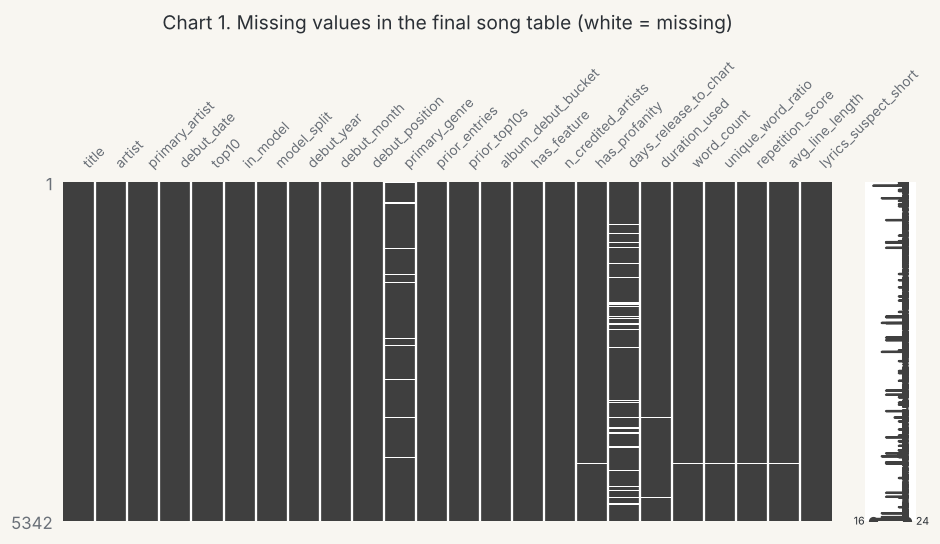

In [46]:
ax = msno.matrix(songs, figsize=(10, 4), fontsize=9)
ax.set_title('Chart 1. Missing values in the final song table (white = missing)', pad=100);

The Top 10 rate is steady at about one in ten across all nine years.

In [47]:
by_year = songs.groupby('debut_year').agg(songs=('title', 'size'), top10=('top10', 'sum'))
by_year['top10_rate'] = (by_year['top10'] / by_year['songs'] * 100).round(1)
by_year

,songs,top10,top10_rate
debut_year,,,
2018,595,67,11.3
2019,518,48,9.3
2020,674,65,9.6
2021,647,63,9.7
2022,629,77,12.2
2023,613,58,9.5
2024,617,63,10.2
2025,570,49,8.6
2026,479,29,6.1


### Summary: what we changed and why

| Column | Issue | Action | Justification |
|---|---|---|---|
| all | the archive has one row per song **per week** | Step 2: `groupby` + `agg` to one row per credit | we analyse songs, not weeks |
| `title`, `artist` | 34 songs were listed under two credits (e.g. "Kanye West" → "Ye") | Step 3: hand-checked rename list | their weeks were split and peaks understated; 5,377 → 5,342 songs, Top 10 521 → 519 |
| `artist` | one credit can name several artists | Step 4: replace separators, then `.str.split` | each artist's history must be counted |
| `artist` | three names contain a separator but are one act | Step 4: protected-names list | "Lil Nas X" would be cut by " x "; Sam & Dave and Sonny & Cher would leak into Dave's and Cher's histories |
| `prior_top10s` | history could include the song itself or later songs | Step 5: count only songs that debuted strictly earlier; two checks | otherwise the predictor would leak the answer |
| `top10` | 99 songs are still on the chart | Step 6: excluded from all tests | their peak is not final |
| `primary_genre` | hundreds of detailed labels | Step 8: keyword rules + vote counts | comparable broad groups |
| `primary_genre` | ties between genres | Step 8: artist's votes break ties, otherwise "mixed" | no arbitrary choice (e.g. alphabetical) |
| `duration` | 382 album-length or placeholder durations | Step 9: MusicBrainz length; 306 repaired | needed for the cut-short check |
| lyrics | some uploads are cut short | Step 9: flag the slowest 2% per genre | flagged for sensitivity checks |
| lyrics | section tags such as `[Chorus]` | Step 10: removed with `.str.replace` | tags are not lyrics |
| lyric measures | 32 songs have no lyrics | Step 10: left blank, not 0 | a missing song is not a zero-word song |

Two problems were fixed earlier, when the collection scripts fetched the data, so the raw
files already include the fixes: LRCLIB sometimes returned an instrumental upload for a song
with vocals (we prefer a version with lyrics), and a search by title alone could return a
different artist's song of the same name (we require the artist to match).

**So what:** after cleaning there is one row per song, every predictor uses only what was known
at debut, and every remaining gap is explained.

## 4. Exploratory questions

Section 4.0 checks the data first. Then come fifteen questions in five themes. Each theme starts
with a main question (Q1-Q5) and adds two follow-ups (a and b) that dig deeper or check whether
the main result survives the most likely confounder. All tests use the 2018-2024 training songs
only. Questions whose answer turned out to be "no detectable difference" were dropped from the main
analysis and are listed in 4.7, so nothing tested is hidden.

| Theme | # | Question | Chart |
|---|---|---|---|
| 4.1 Genre | Q1 | Which genres have the highest share of songs reaching the Top 10? | 1 |
| | Q1a | Do genre differences persist after excluding songs that debuted alongside other songs by the same artist? | 2 |
| | Q1b | Within each genre, how do songs by artists with and without a previous Top 10 compare? | 3 |
| 4.2 Artist track record | Q2 | How does the Top 10 rate change with the number of Top 10 hits the artist had reached before the song's debut? | 4 |
| | Q2a | Among experienced artists, is the share of their earlier songs that reached the Top 10 (hit ratio) associated with success? | 5 |
| | Q2b | Among artists without a previous Top 10, how does the rate vary with the number of earlier chart entries? | 6 |
| 4.3 Artist reach | Q3 | How concentrated are Top 10 songs among a small number of artists? | 7 |
| | Q3a | Do songs by artists from outside the US reach the Top 10 more often than songs by US artists? | 8 |
| | Q3b | Does the origin gap hold among artists with a similar number of previous hits? | 9 |
| 4.4 Release strategy | Q4 | Is the number of songs an artist debuts in the same week associated with Top 10 success? | 10 |
| | Q4a | Do singles and album tracks differ, and does any gap remain among songs debuting alone? | 11 |
| | Q4b | Is the same-week debut pattern found in both hip-hop and pop? | 12 |
| 4.5 Timing and lyrics | Q5 | Does the Top 10 rate differ by chart debut month, and does any difference survive excluding big same-artist debut weeks? | 13 |
| | Q5a | How did the genre make-up of Top 10 songs change, and did any genre's own Top 10 rate change? | 14 |
| | Q5b | Do Top 10 songs differ from other songs on four lyric measures? | 15 |

#### How each question is laid out

1. Research question: what is being compared, and the hypothesis.
2. Data analysis: the Top 10 rate and sample size for each group, and the statistical test.
3. Visualization: a chart whose headline states the result, with percentages and sample sizes.
4. Finding: one or two sentences with the actual numbers.
5. Interpretation: what the result suggests, without claiming causation or overstating significance.

#### Terms used throughout

- Previous Top 10: the lead artist had reached the Top 10 with an earlier song before this song's debut week (4.0c explains why "before the debut" matters).
- Hit ratio: the share of the lead artist's earlier Hot 100 entries that had reached the Top 10 by this song's debut.
- Only debut that week (or "debuting alone"): no other song by the same lead artist entered the Hot 100 in the same week.
- Origin: the lead artist's country as recorded in MusicBrainz.
- Top 10 rate: the share of songs in a group that ever reached positions 1-10.

#### Tests used

Chi-square compares Top 10 rates across groups, with Cramér's V as the effect size. Mann-Whitney U
compares a number, such as word count, between Top 10 songs and the rest, with the rank-biserial r
as the effect size. With about 4,300 songs almost anything can reach significance, so the effect
size says whether a difference is large enough to matter. Significance is read at α = 0.05.

#### How to read the results

- Null hypothesis (H₀): the default, "this factor makes no difference". We only claim a difference when the data make that default very unlikely.
- p-value: how surprising the result would be if the factor truly made no difference. Below 0.05, we treat the difference as real.
- Cramér's V (0 to 1) and rank-biserial r (-1 to 1): how big the effect is. Under 0.1 in size is negligible, 0.1 to 0.3 is small.
- A non-significant result is not proof of no difference, only a lack of evidence for one.
- Every result is an association. Nothing here was randomised, so none of it shows cause and effect.

In [48]:
# Test helpers reused by every question:
#   chi_square()   compares Top 10 rates across groups; Cramér's V is the effect size
#   report()       prints the test result and the table of rates
#   mann_whitney() compares a number (e.g. word count) between Top 10 songs and the rest; r is the effect size
ALPHA = 0.05

def chi_square(data, column):
    table = pd.crosstab(data[column], data["top10"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    summary = pd.DataFrame({"songs": table.sum(axis=1), "top10": table[True],
                            "top10_rate_pct": (table[True] / table.sum(axis=1) * 100).round(1)})
    return {"chi2": chi2, "p": p, "dof": dof, "v": v, "summary": summary}

def report(result, name):
    verdict = "REJECT the null" if result["p"] < ALPHA else "cannot reject the null"
    v = result["v"]
    strength = "negligible" if v < 0.1 else "small" if v < 0.3 else "moderate" if v < 0.5 else "large"
    print(f"{name}\n" + "-" * len(name))
    print(f"  chi2({result['dof']}) = {result['chi2']:.1f}   p = {result['p']:.3g}   Cramer's V = {v:.3f} ({strength})")
    print(f"  -> {verdict} at alpha = {ALPHA}\n")
    display(result["summary"])

def mann_whitney(data, column):
    """Mann-Whitney U plus the rank-biserial r (-1 to 1; positive = Top 10 songs tend to score higher)."""
    a, b = data.loc[data["top10"], column].dropna(), data.loc[~data["top10"], column].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"p": p, "effect_r": 2 * u / (len(a) * len(b)) - 1, "median_top10": a.median(),
            "median_other": b.median(), "n_top10": len(a), "n_other": len(b)}

### 4.0 Checks before the analysis

Three checks come before any question: (a) the sample totals in the notebook match the CSV, and each
question's base is stated; (b) missing values are counted and handled explicitly; (c) the artist-history
measures only use information available before each song's debut.

In [49]:
# 4.0a: a stricter count of previous hits (used from 4.0c on), then reconcile the sample totals.
# Built from Section 3's tables: an earlier song only counts if it had ALREADY reached the Top 10
# before this song's debut week (prior_top10s counts it if it got there at any time).
first_top10 = weekly[weekly["position"] <= 10].groupby(["title", "artist"])["chart_date"].min().reset_index()
first_top10.columns = ["earlier_title", "earlier_artist", "earlier_first_top10"]
known = pd.merge(earlier, first_top10, on=["earlier_title", "earlier_artist"], how="left")
known = known[known["earlier_first_top10"] < known["debut_date"]]
strict = known.groupby(["title", "artist"]).size().reset_index(name="prior_top10s_known")
df = df.merge(strict, on=["title", "artist"], how="left", validate="one_to_one")
df["prior_top10s_known"] = df["prior_top10s_known"].fillna(0)
print("songs with at least one hit known at debut:", (df["prior_top10s_known"] > 0).sum(), "of", len(df))


train, test, excluded = df[df["model_split"] == "train"].copy(), df[df["model_split"] == "test"], df[~df["in_model"]]
groups = {"songs_analysis.csv (all songs)": df, "train: debuted 2018-2024": train,
          "test: debuted 2025-2026 (held out)": test, "still charting (no final peak)": excluded}
totals = pd.DataFrame({"songs": [len(g) for g in groups.values()], "top10": [g["top10"].sum() for g in groups.values()]},
                      index=list(groups))
totals.loc["train + test + still charting"] = totals.iloc[1:].sum()
totals["top10_rate_pct"] = (totals["top10"] / totals["songs"] * 100).round(1)
display(totals)

# The base each question works from (training songs only).
display(pd.Series({
    "all training songs (Q2, Q3, Q4, Q5)": len(train),
    "with a genre (Q1, Q1b, Q5a)": train["primary_genre"].notna().sum(),
    "with a genre and debuting alone (Q1a)": (train["primary_genre"].notna() & (train["album_debut_bucket"] == "1")).sum(),
    "no previous Top 10 (Q2b)": (train["prior_top10s_known"] == 0).sum(),
    "single, album or EP release (Q4a)": train["release_type"].isin(["Single", "Album", "EP"]).sum(),
    "with lyrics (Q5b)": train["word_count"].notna().sum(),
    "lead artist with 3+ earlier entries (Q2a)": (train["prior_entries"] >= 3).sum(),
    "hip-hop or pop (Q4b)": train["primary_genre"].isin(["hip-hop/rap", "pop"]).sum(),
    "Top 10 songs (Q3, Q5a)": train["top10"].sum()}, name="songs").to_frame())

songs with at least one hit known at debut: 3450 of 5342


,songs,top10,top10_rate_pct
songs_analysis.csv (all songs),5342,519,9.7
train: debuted 2018-2024,4293,441,10.3
test: debuted 2025-2026 (held out),950,56,5.9
still charting (no final peak),99,22,22.2
train + test + still charting,5342,519,9.7


,songs
"all training songs (Q2, Q3, Q4, Q5)",4293
"with a genre (Q1, Q1b, Q5a)",4176
with a genre and debuting alone (Q1a),2031
no previous Top 10 (Q2b),1524
"single, album or EP release (Q4a)",4184
with lyrics (Q5b),4274
lead artist with 3+ earlier entries (Q2a),3494
hip-hop or pop (Q4b),2813
"Top 10 songs (Q3, Q5a)",441


In [50]:
# 4.0b: missing values in the columns Section 4 uses (training songs), and how each is handled.
used = {"primary_genre": "left out of genre questions",
        "release_type": "left out of Q4a (with the 109 songs of other release types)",
        "word_count": "no lyrics: left out of lyric questions, never counted as 0",
        "artist_mbids": "no MusicBrainz artist: origin unknown, left out of Q3a and Q3b",
        "prior_top10s_known": "must be 0 missing"}
display(pd.DataFrame({"missing": train[list(used)].isna().sum(),
                      "pct_of_train": (train[list(used)].isna().mean() * 100).round(1), "handling": used}))


,missing,pct_of_train,handling
primary_genre,117,2.7,left out of genre questions
release_type,58,1.4,left out of Q4a (with the 109 songs of other r...
word_count,19,0.4,"no lyrics: left out of lyric questions, never ..."
artist_mbids,47,1.1,"no MusicBrainz artist: origin unknown, left ou..."
prior_top10s_known,0,0.0,must be 0 missing


In [51]:
# 4.0c: prior_top10s (original pipeline) counts earlier songs that EVENTUALLY reached the Top 10, even after this
# song debuted. prior_top10s_known only counts hits already reached before this song's debut week.
changed = train["prior_top10s"] != train["prior_top10s_known"]
print(f"training songs where the two counts differ: {changed.sum()} of {len(train):,} ({changed.mean():.1%})")
hit_groups, hit_labels = [-1, 0, 4, 9, np.inf], ["0", "1-4", "5-9", "10+"]
display(pd.concat({
    "eventual hits (original)": chi_square(train.assign(g=pd.cut(train["prior_top10s"], hit_groups, labels=hit_labels)), "g")["summary"],
    "hits known at debut (used below)": chi_square(train.assign(g=pd.cut(train["prior_top10s_known"], hit_groups, labels=hit_labels)), "g")["summary"]},
    axis=1))

# Use the strict version everywhere in Section 4.
train["prior_hits"] = train["prior_top10s_known"]
train["prior_hit_group"] = pd.cut(train["prior_hits"], hit_groups, labels=hit_labels)
train["artist_status"] = np.where(train["prior_hits"] > 0, "Previous Top 10", "No previous Top 10")
print(train["artist_status"].value_counts())

training songs where the two counts differ: 400 of 4,293 (9.3%)


eventual hits (original)                      hits known at debut (used below)                     
                       songs top10 top10_rate_pct                            songs top10 top10_rate_pct
g                                                                                                      
0                       1476    85            5.8                             1524    88            5.8
1-4                     1452   127            8.7                             1416   126            8.9
5-9                      458    61           13.3                              456    61           13.4
10+                      907   168           18.5                              897   166           18.5

artist_status
Previous Top 10       2769
No previous Top 10    1524
Name: count, dtype: int64


**What the checks show.** The CSV's 5,342 songs split exactly into 4,293 training songs, 950 held-out
test songs and 99 still charting. The strict history count is built from the tables in Section 3 (Step 5)
and matches every song in the CSV. Missing values
are small except release dates (9.2% of training songs), and each question works from the base listed
above.

The original count of previous Top 10s included songs that reached the Top 10 only after the song being
analysed had debuted. That affects 400 training songs (9.3%), almost always by one hit. Section 4 uses the
strict count, which only includes hits already reached at debut. It changes the Q2 rates by at most 0.1
points, so the earlier findings stand, but now every artist-history measure is knowable at debut.

### 4.1 Genre

Q1 compares genres. Q1a checks whether the gaps come from some genres debuting more songs at once, and
Q1b compares artists with and without a previous hit inside each genre.

#### Q1. Which genres have the highest share of songs reaching the Top 10?

**Research question.** We compare the Top 10 rate across the nine broad genres, using the 4,176 training
songs that have a genre label.

**Hypothesis.** H₀: the Top 10 rate is the same in every genre. H₁: it differs.

In [52]:
# Q1 test: compare Top 10 rates across genres (songs with a genre label).
q1 = chi_square(train, "primary_genre")
report(q1, "Q1: Top 10 rate by primary genre")
genre_order = q1["summary"].sort_values("top10_rate_pct", ascending=False).index    # used by Charts 1-3

Q1: Top 10 rate by primary genre
--------------------------------
  chi2(8) = 89.0   p = 7.35e-16   Cramer's V = 0.146 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
primary_genre,,,
Latin,158,11,7.0
R&B,321,30,9.3
country,510,27,5.3
dance/electronic,106,17,16.0
hip-hop/rap,2017,178,8.8
mixed,64,3,4.7
other,110,8,7.3
pop,796,149,18.7
rock/alternative,94,13,13.8


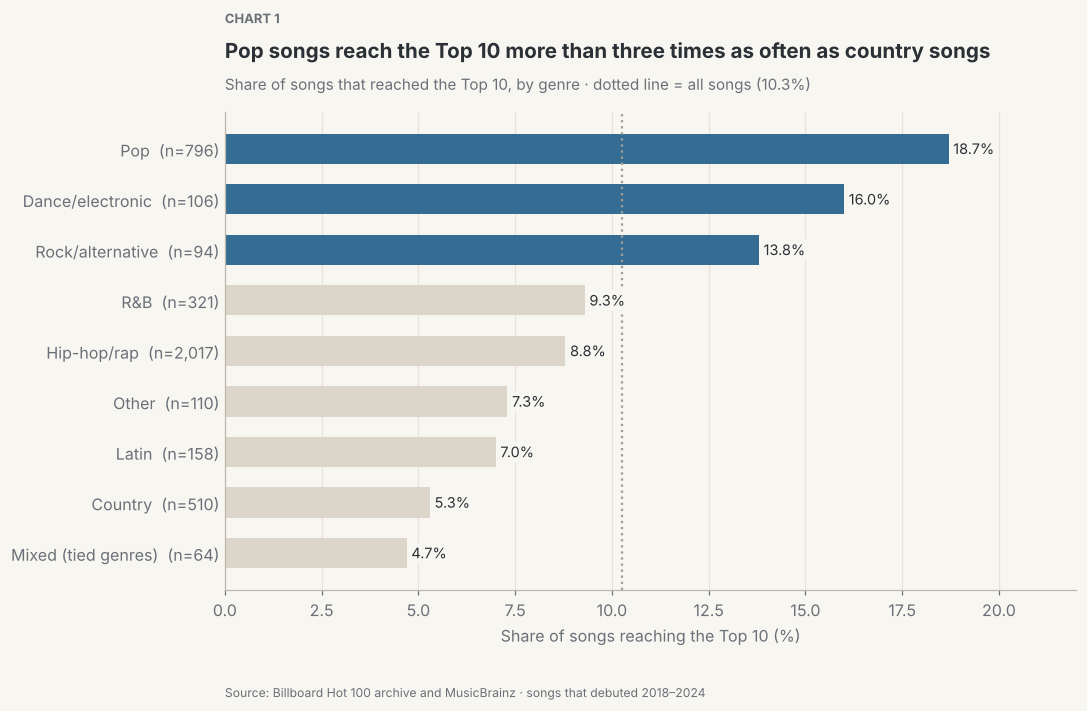

In [53]:
# Chart 1 — sorted horizontal bars; genres above the all-song rate in slate.
data = q1["summary"].loc[genre_order]
overall = train["top10"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 5.5))
bars(ax, [f"{GENRE_NAMES[g]}  (n={n:,})" for g, n in zip(data.index, data["songs"])],
     [("", data["top10_rate_pct"], [FOCUS if r > overall else CONTEXT for r in data["top10_rate_pct"]])], horizontal=True)
ax.axvline(overall, color=REF, linestyle=":", zorder=1)
ax.set(xlabel=RATE_LABEL, xlim=(0, 22))
finish(fig, ax, 1, "Pop songs reach the Top 10 more than three times as often as country songs",
       f"Share of songs that reached the Top 10, by genre · dotted line = all songs ({overall:.1f}%)")

**Finding.** Pop has the highest Top 10 rate (18.7% of 796 songs) and country one of the lowest (5.3% of
510), against 10.3% overall. Genre and Top 10 status are associated (χ²(8) = 89.0, p < 0.001), with a small
effect size (V = 0.146).

**Interpretation.** Pop songs reach the Top 10 about 3.5 times as often as country songs, so genre shifts
the odds without deciding them. Genre also travels with who releases a song and how, which Q1a and Q1b
look at. Labels come from MusicBrainz volunteers; the 117 training songs without a genre are left out, and
the 64 "mixed" songs are ties between two genres.

#### Q1a. Do genre differences persist after excluding songs that debuted alongside other songs by the same artist?

**Research question.** We compare each genre's Top 10 rate for all songs with its rate among songs that
were the artist's only Hot 100 debut that week (2,031 songs with a genre). Q4 shows that songs debuting
alongside several others reach the Top 10 less often, and some genres do that far more than others.

**Hypothesis.** H₀: among songs debuting alone, the Top 10 rate is the same in every genre. H₁: it still
differs.

In [54]:
# Q1a test: repeat Q1 using only songs that were the artist's only chart debut that week.
alone = train[train["album_debut_bucket"] == "1"]
print("Share of each genre's songs that debuted alongside other songs by the same artist (%)")
display((train["album_debut_bucket"] != "1").groupby(train["primary_genre"]).mean().mul(100).round(1)
        .sort_values(ascending=False).to_frame("pct_multi_debut").T)
q1a = chi_square(alone, "primary_genre")
report(q1a, "Q1a: Top 10 rate by genre, excluding same-week multi-song debuts")

Share of each genre's songs that debuted alongside other songs by the same artist (%)


primary_genre,hip-hop/rap,R&B,Latin,pop,rock/alternative,mixed,country,dance/electronic,other
pct_multi_debut,66.3,59.2,41.8,37.6,31.9,29.7,28.4,28.3,25.5


Q1a: Top 10 rate by genre, excluding same-week multi-song debuts
----------------------------------------------------------------
  chi2(8) = 63.4   p = 1.02e-10   Cramer's V = 0.177 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
primary_genre,,,
Latin,92,5,5.4
R&B,131,17,13.0
country,365,17,4.7
dance/electronic,76,13,17.1
hip-hop/rap,679,74,10.9
mixed,45,3,6.7
other,82,8,9.8
pop,497,103,20.7
rock/alternative,64,5,7.8


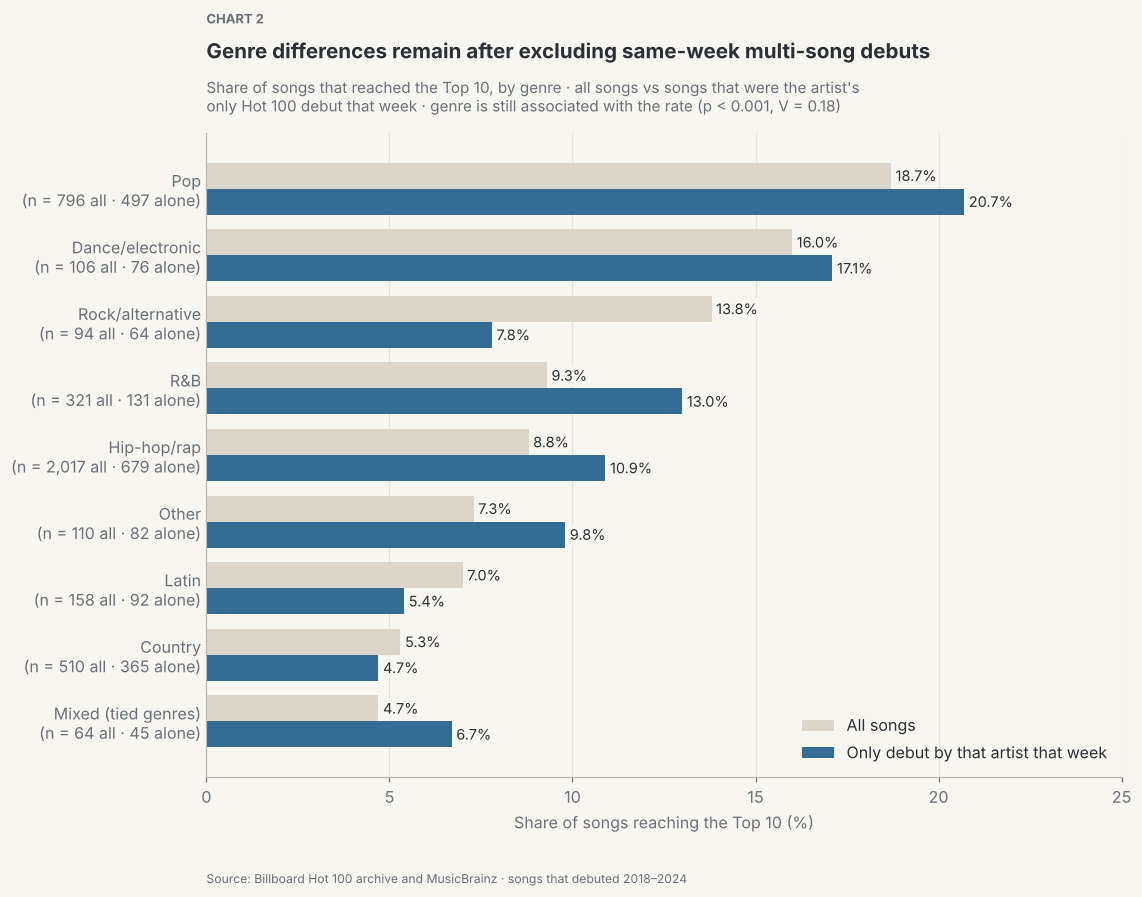

In [55]:
# Chart 2 — grouped horizontal bars: all songs vs songs debuting alone, same genre order as Chart 1.
a, b = q1["summary"].loc[genre_order], q1a["summary"].loc[genre_order]
fig, ax = plt.subplots(figsize=(10.5, 7))
bars(ax, [f"{GENRE_NAMES[g]}\n(n = {x:,} all · {y:,} alone)" for g, x, y in zip(genre_order, a["songs"], b["songs"])],
     [("All songs", a["top10_rate_pct"], CONTEXT), ("Only debut by that artist that week", b["top10_rate_pct"], FOCUS)],
     horizontal=True)
ax.set(xlabel=RATE_LABEL, xlim=(0, 25))
ax.legend(loc="lower right")
finish(fig, ax, 2, "Genre differences remain after excluding same-week multi-song debuts",
       "Share of songs that reached the Top 10, by genre · all songs vs songs that were the artist's\n"
       f"only Hot 100 debut that week · genre is still associated with the rate (p < 0.001, V = {q1a['v']:.2f})")

**Finding.** Among songs debuting alone, genre is still associated with the Top 10 rate (χ²(8) = 63.4,
p < 0.001, V = 0.177): pop 20.7% against country 4.7%. Hip-hop (66.3%) and R&B (59.2%) have the largest
shares of songs debuting alongside others, and their rates rise most when those songs are excluded
(8.8% to 10.9% and 9.3% to 13.0%).

**Interpretation.** Same-week multi-song debuts account for part of hip-hop's and R&B's lower overall rates,
but not for the genre gap as a whole. Small genres rest on very few hits once filtered (5 each for Latin and
rock/alternative), so only the large genres should be read closely. Rock/alternative falls from 13.8% to
7.8%, which suggests a few multi-song weeks lifted its overall figure.

#### Q1b. Within each genre, how do songs by artists with and without a previous Top 10 compare?

**Research question.** Inside each genre, we compare the Top 10 rate of songs whose lead artist had a
previous Top 10 at debut with songs whose lead artist had none. The chart shows the five genres with at
least 50 songs in both groups.

**Hypothesis.** H₀: within a genre, the Top 10 rate is the same for both groups. H₁: it differs.

In [56]:
# Q1b test: within each genre, compare artists with and without a previous Top 10.
rows = {}
for genre, g in train.groupby("primary_genre"):
    r = chi_square(g, "artist_status")
    s = r["summary"]
    rows[genre] = {"n_without": s.loc["No previous Top 10", "songs"], "n_with": s.loc["Previous Top 10", "songs"],
                   "rate_without": s.loc["No previous Top 10", "top10_rate_pct"],
                   "rate_with": s.loc["Previous Top 10", "top10_rate_pct"],
                   "gap_pts": round((g.loc[g["prior_hits"] > 0, "top10"].mean() - g.loc[g["prior_hits"] == 0, "top10"].mean()) * 100, 1),
                   "p_value": round(r["p"], 4)}
q1b = pd.DataFrame.from_dict(rows, orient="index").sort_values("n_without", ascending=False)
display(q1b)
report(chi_square(train, "artist_status"), "All genres: previous Top 10 vs none")

,n_without,n_with,rate_without,rate_with,gap_pts,p_value
hip-hop/rap,539,1478,3.9,10.6,6.7,0.0000
country,295,215,3.1,8.4,5.3,0.0143
pop,222,574,16.7,19.5,2.8,0.4112
R&B,141,180,5.0,12.8,7.8,0.0283
Latin,86,72,3.5,11.1,7.6,0.1185
other,64,46,4.7,10.9,6.2,0.3901
dance/electronic,34,72,11.8,18.1,6.3,0.5890
mixed,31,33,6.5,3.0,-3.4,0.9558
rock/alternative,23,71,4.3,16.9,12.6,0.2427


All genres: previous Top 10 vs none
-----------------------------------
  chi2(1) = 51.1   p = 8.71e-13   Cramer's V = 0.109 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
artist_status,,,
No previous Top 10,1524,88,5.8
Previous Top 10,2769,353,12.7


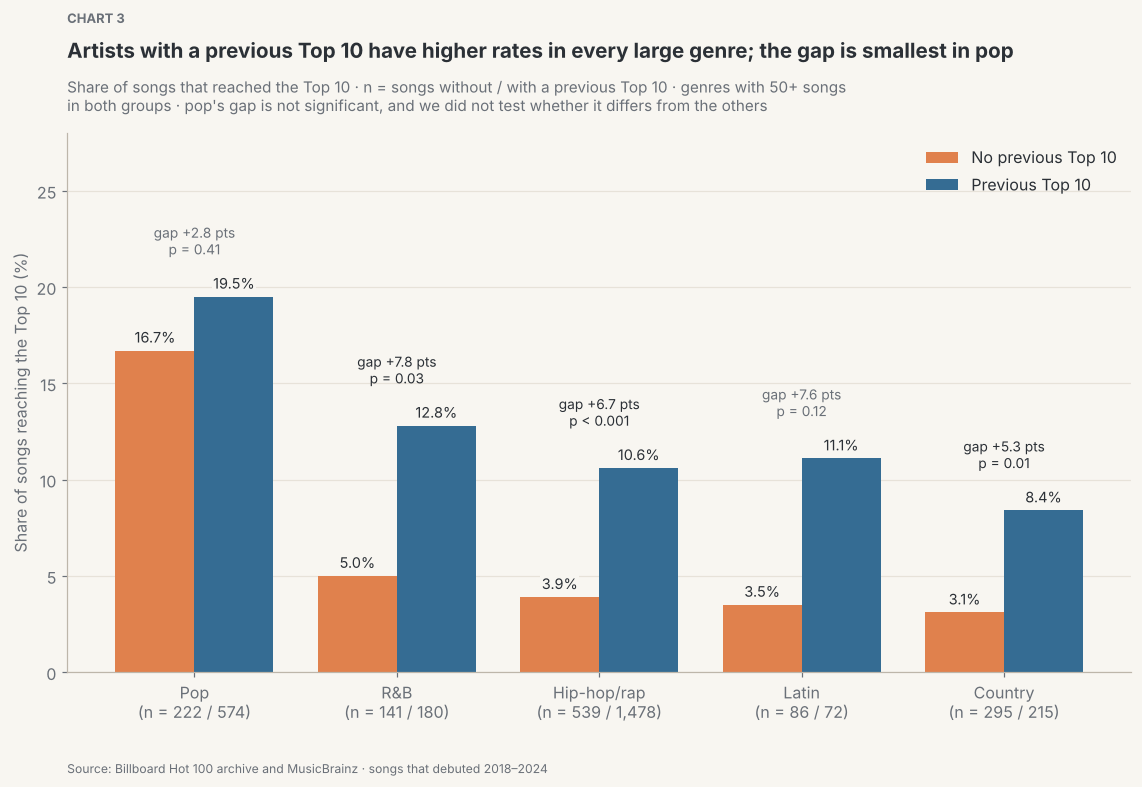

In [57]:
# Chart 3 — grouped bars per genre (50+ songs in both groups), with the gap and its p-value above each pair.
shown = q1b.loc[[g for g in genre_order if q1b.loc[g, "n_without"] >= 50 and q1b.loc[g, "n_with"] >= 50]]
fig, ax = plt.subplots(figsize=(10.5, 6))
bars(ax, [f"{GENRE_NAMES[g]}\n(n = {a:,} / {b:,})" for g, a, b in zip(shown.index, shown["n_without"], shown["n_with"])],
     [("No previous Top 10", shown["rate_without"], SECOND), ("Previous Top 10", shown["rate_with"], FOCUS)])
for i, (gap, p, top) in enumerate(zip(shown["gap_pts"], shown["p_value"], shown[["rate_with", "rate_without"]].max(axis=1))):
    ax.text(i, top + 2.2, f"gap {gap:+.1f} pts\n" + ("p < 0.001" if p < 0.001 else f"p = {p:.2f}"),
            ha="center", fontsize=9, color=TEXT if p < ALPHA else MUTED)
ax.set(ylabel=RATE_LABEL, ylim=(0, 28))
finish(fig, ax, 3, "Artists with a previous Top 10 have higher rates in every large genre; the gap is smallest in pop",
       "Share of songs that reached the Top 10 · n = songs without / with a previous Top 10 · genres with 50+ songs\n"
       "in both groups · pop's gap is not significant, and we did not test whether it differs from the others")

**Finding.** Songs by artists with a previous Top 10 have higher rates in all five large genres. The gap is
significant in hip-hop (3.9% vs 10.6%, p < 0.001), country (3.1% vs 8.4%, p = 0.014) and R&B (5.0% vs
12.8%, p = 0.028), but not in pop (16.7% vs 19.5%, p = 0.41) or Latin (3.5% vs 11.1%, p = 0.12, with only
86 and 72 songs).

**Interpretation.** Pop is the one large genre where songs by artists without a previous hit reach the Top
10 at a rate close to those with one. That is worth noting, but it does not show pop is easier to break
into: a non-significant gap is not evidence of no gap, and we have not tested whether pop's gap is
significantly smaller than the other genres' (that needs a model with a genre-by-history interaction).
We also cannot see label or marketing support behind each song.

**Theme takeaway:** genre is associated with Top 10 rates even after excluding same-week multi-song debuts
(Q1a). Artists with a previous hit have higher rates in every large genre; the gap is smallest in pop, but
we have not shown that pop's gap is genuinely different (Q1b).

### 4.2 Artist track record

Q2 relates an artist's previous hits to the next song's chances. Q2a asks whether the artist's hit
ratio adds information, and Q2b looks inside the group with no previous hit. All counts use only hits
reached before each song's debut (4.0c).

#### Q2. How does the Top 10 rate change with the number of Top 10 hits the artist had reached before the song's debut?

**Research question.** We compare the Top 10 rate across four groups of lead artists: no previous Top 10,
1-4, 5-9, and 10 or more. A previous song only counts if it had reached the Top 10 before this song's
debut week (all 4,293 training songs).

**Hypothesis.** H₀: the number of previous hits is unrelated to reaching the Top 10. H₁: artists with more
previous hits have higher rates.

In [58]:
# Q2 test: Top 10 rate by the lead artist's Top 10 hits reached BEFORE this song's debut (groups made in 4.0c).
q2 = chi_square(train, "prior_hit_group")
report(q2, "Q2: Top 10 rate by previous Top 10 hits (known at debut)")
HIT_NAMES = ["None", "1–4", "5–9", "10 or more"]                       # chart labels for the four groups

Q2: Top 10 rate by previous Top 10 hits (known at debut)
--------------------------------------------------------
  chi2(3) = 107.1   p = 4.62e-23   Cramer's V = 0.158 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
prior_hit_group,,,
0,1524,88,5.8
1-4,1416,126,8.9
5-9,456,61,13.4
10+,897,166,18.5


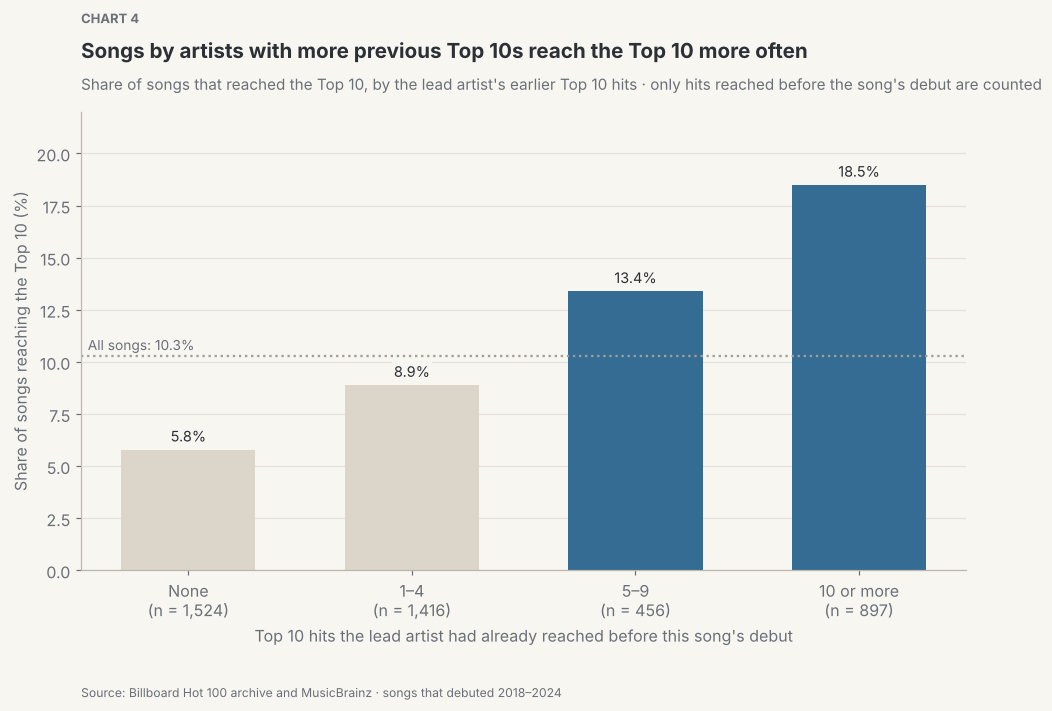

In [59]:
# Chart 4 — bars by previous-hit group; groups above the all-song rate in slate.
data, overall = q2["summary"], train["top10"].mean() * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
bars(ax, [f"{g}\n(n = {n:,})" for g, n in zip(HIT_NAMES, data["songs"])],
     [("", data["top10_rate_pct"], [FOCUS if r > overall else CONTEXT for r in data["top10_rate_pct"]])])
ax.axhline(overall, color=REF, linestyle=":", zorder=1)
ax.text(-0.45, overall + 0.3, f"All songs: {overall:.1f}%", fontsize=9, color=MUTED)
ax.set(xlabel="Top 10 hits the lead artist had already reached before this song's debut", ylabel=RATE_LABEL, ylim=(0, 22))
finish(fig, ax, 4, "Songs by artists with more previous Top 10s reach the Top 10 more often",
       "Share of songs that reached the Top 10, by the lead artist's earlier Top 10 hits · "
       "only hits reached before the song's debut are counted")

**Finding.** The Top 10 rate rises steadily with previous hits: 5.8% for artists with none (1,524 songs), 8.9%
for 1-4, 13.4% for 5-9 and 18.5% for 10 or more (χ²(3) = 107.1, p < 0.001, V = 0.158).

**Interpretation.** Songs by artists with ten or more previous hits reach the Top 10 about three times as
often as songs by artists with none. This describes artists rather than songs, and it is partly
self-reinforcing: established artists also get more playlist placement and marketing, which we cannot see.
Counting only hits reached before the debut changes 9.3% of the counts but barely moves these rates (4.0c).

#### Q2a. Among experienced artists, is the share of their earlier songs that reached the Top 10 (hit ratio) associated with success?

**Research question.** For songs whose lead artist had at least 3 earlier Hot 100 entries (3,494 songs), we
compare Top 10 rates across four hit-ratio groups: 0%, 1-10%, 11-25% and over 25% of earlier entries having
reached the Top 10 before this song's debut. We then repeat the comparison within artists who have the same
number of previous hits, to see whether the ratio says more than the count.

**Hypothesis.** H₀: the Top 10 rate is the same in every hit-ratio group. H₁: artists with a higher hit ratio
have higher rates.

In [60]:
# Q2a test: among lead artists with 3+ earlier chart entries, Top 10 rate by hit ratio
# (the share of those earlier entries that had reached the Top 10 before this song's debut).
experienced = train[train["prior_entries"] >= 3].copy()
experienced["hit_ratio_group"] = pd.cut((experienced["prior_hits"] / experienced["prior_entries"]).clip(upper=1),
                                        [-0.01, 0, 0.10, 0.25, 1.0], labels=["0%", "1–10%", "11–25%", "Over 25%"])
q2a = chi_square(experienced, "hit_ratio_group")
report(q2a, "Q2a: Top 10 rate by hit ratio (artists with 3+ earlier entries)")

# Does hit ratio still separate artists with the same NUMBER of previous hits?
q2a_within = {}
for group, g in experienced[experienced["prior_hits"] > 0].groupby("prior_hit_group", observed=True):
    r = chi_square(g, "hit_ratio_group")
    q2a_within[group] = {**{f"rate_{k}": v for k, v in r["summary"]["top10_rate_pct"].items()}, "p_value": round(r["p"], 4)}
q2a_within = pd.DataFrame.from_dict(q2a_within, orient="index").rename_axis("previous_hits")
display(q2a_within)

Q2a: Top 10 rate by hit ratio (artists with 3+ earlier entries)
---------------------------------------------------------------
  chi2(3) = 96.8   p = 7.6e-21   Cramer's V = 0.166 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
hit_ratio_group,,,
0%,783,28,3.6
1–10%,869,62,7.1
11–25%,1314,203,15.4
Over 25%,528,82,15.5


,rate_1–10%,rate_11–25%,rate_Over 25%,p_value
previous_hits,,,,
1-4,6.9,9.6,14.1,0.0048
5-9,6.2,16.1,13.2,0.0778
10+,10.7,19.3,19.1,0.1885


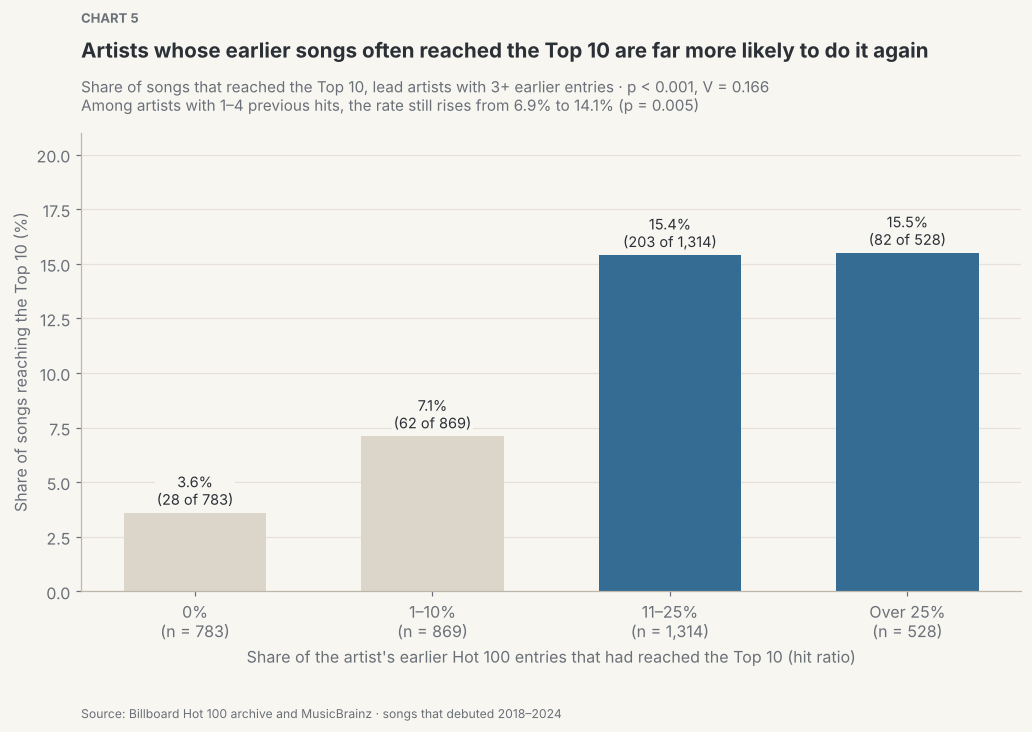

In [61]:
# Chart 5 — bars by hit ratio, labelled with the rate and Top 10 songs out of all songs.
data, within = q2a["summary"], q2a_within.loc["1-4"]
fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars(ax, [f"{g}\n(n = {n:,})" for g, n in zip(data.index, data["songs"])], [("", data["top10_rate_pct"], [CONTEXT, CONTEXT, FOCUS, FOCUS])],
     bar_labels=[f"{r:.1f}%\n({k} of {n:,})" for r, k, n in zip(data["top10_rate_pct"], data["top10"], data["songs"])])
ax.set(xlabel="Share of the artist's earlier Hot 100 entries that had reached the Top 10 (hit ratio)", ylabel=RATE_LABEL, ylim=(0, 21))
finish(fig, ax, 5, "Artists whose earlier songs often reached the Top 10 are far more likely to do it again",
       f"Share of songs that reached the Top 10, lead artists with 3+ earlier entries · p < 0.001, V = {q2a['v']:.3f}\n"
       f"Among artists with 1–4 previous hits, the rate still rises from {within['rate_1–10%']:.1f}% to "
       f"{within['rate_Over 25%']:.1f}% (p = {within['p_value']:.3f})")

**Finding.** The Top 10 rate climbs from 3.6% for artists with no earlier hits to 7.1% at a 1-10% hit ratio
and about 15.5% above 10% (χ²(3) = 96.8, p < 0.001, V = 0.166). Among artists with 1-4 previous hits, the
ratio still separates them: 6.9% at 1-10% against 14.1% above 25% (p = 0.005).

**Interpretation.** How often an artist's songs become hits is at least as informative as how many hits they
have: its effect size (V = 0.166) is slightly larger than the hit count's in Q2 (V = 0.158). Within the 5-9 and
10+ hit groups the ratio does not add a significant difference (p = 0.08 and p = 0.19), so the extra information
is mostly about less-established artists. The two measures overlap heavily; whether both belong in a model is a
question for the modelling phase.

#### Q2b. Among artists without a previous Top 10, how does the rate vary with the number of earlier chart entries?

**Research question.** Among the 1,524 songs by artists with no previous Top 10, we compare the Top 10 rate
by how many Hot 100 entries the artist had before: none (first entry), 1-2, 3-5, 6-10, or 11 or more.

**Hypothesis.** H₀: the Top 10 rate is the same however many times the artist has charted before. H₁: it
differs.

In [62]:
# Q2b test: among artists with no previous Top 10, Top 10 rate by number of earlier chart entries.
never_hit = train[train["prior_hits"] == 0].copy()
never_hit["earlier_entries"] = pd.cut(never_hit["prior_entries"], [-1, 0, 2, 5, 10, np.inf],
                                      labels=["First entry", "1–2", "3–5", "6–10", "11+"])
q2b = chi_square(never_hit, "earlier_entries")
report(q2b, "Q2b: no previous Top 10, by number of earlier chart entries")
print("Songs that were the artist's only debut that week:")
display(chi_square(never_hit[never_hit["album_debut_bucket"] == "1"], "earlier_entries")["summary"])

Q2b: no previous Top 10, by number of earlier chart entries
-----------------------------------------------------------
  chi2(4) = 20.1   p = 0.000488   Cramer's V = 0.115 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
earlier_entries,,,
First entry,438,41,9.4
1–2,303,19,6.3
3–5,266,12,4.5
6–10,177,9,5.1
11+,340,7,2.1


Songs that were the artist's only debut that week:


,songs,top10,top10_rate_pct
earlier_entries,,,
First entry,380,38,10.0
1–2,259,19,7.3
3–5,201,10,5.0
6–10,134,6,4.5
11+,155,2,1.3


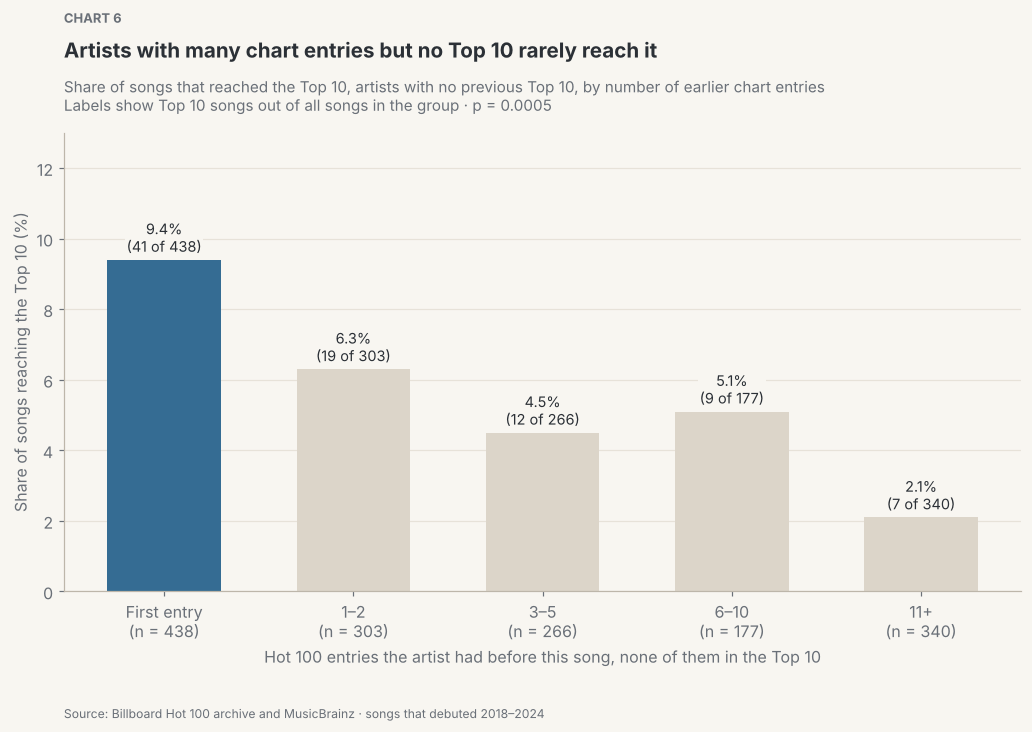

In [63]:
# Chart 6 — bars by earlier entries, labelled with the rate and Top 10 songs out of all songs.
data = q2b["summary"]
fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars(ax, [f"{g}\n(n = {n:,})" for g, n in zip(data.index, data["songs"])], [("", data["top10_rate_pct"], [FOCUS] + [CONTEXT] * 4)],
     bar_labels=[f"{r:.1f}%\n({k} of {n:,})" for r, k, n in zip(data["top10_rate_pct"], data["top10"], data["songs"])])
ax.set(xlabel="Hot 100 entries the artist had before this song, none of them in the Top 10", ylabel=RATE_LABEL, ylim=(0, 13))
finish(fig, ax, 6, "Artists with many chart entries but no Top 10 rarely reach it",
       "Share of songs that reached the Top 10, artists with no previous Top 10, by number of earlier chart entries\n"
       f"Labels show Top 10 songs out of all songs in the group · p = {q2b['p']:.4f}")

**Finding.** A first chart entry reaches the Top 10 9.4% of the time (41 of 438 songs), against 2.1% for
artists with 11 or more earlier entries (7 of 340), with the groups in between at 4.5-6.3% (χ²(4) = 20.1,
p < 0.001, V = 0.115).

**Interpretation.** The "no previous hit" group mixes very different artists: those on their first entry sit
near the overall average, while long-time chart regulars without a hit rarely reach the Top 10. The pattern
holds for songs debuting alone too (10.0% vs 1.3%), so it is not just multi-song weeks. The middle groups
rest on 9-19 hits each, so their exact order should not be read into.

**Theme takeaway:** previous Top 10s counted at debut are strongly associated with success (Q2). The share of an
artist's songs that became hits is at least as telling as the count, especially for artists with 1-4 hits (Q2a),
and among artists without a hit, first-time entrants do far better than long-time chart regulars (Q2b).

### 4.3 Artist reach

Q3 measures how concentrated Top 10 songs are among a few artists. Q3a compares artists from inside and
outside the US, and Q3b checks whether that gap is really about track record.

#### Q3. How concentrated are Top 10 songs among a small number of artists?

**Research question.** We rank lead artists by how many Top 10 songs they had in 2018-2024 and measure what
share of all Top 10 songs, and of all songs, the top 5, 10, 25 and 50 artists account for.

**Hypothesis.** This question is descriptive, so there is no significance test: grouping artists by their own
hits and then testing their hit rate would be circular. The expectation is that Top 10 songs are far more
concentrated than songs in general.

In [64]:
# Q3 analysis: how concentrated are Top 10 songs among lead artists? (Descriptive: a share needs no test,
# and grouping artists by their own hits would make a test circular.)
hits_by_artist = train[train["top10"]].groupby("primary_artist").size().sort_values(ascending=False)
songs_by_artist = train.groupby("primary_artist").size()
print(f"lead artists with at least one song: {songs_by_artist.size:,}; with at least one Top 10: {hits_by_artist.size}")
cum_hits = hits_by_artist.cumsum() / hits_by_artist.sum() * 100                   # top k artists' share of Top 10 songs
cum_songs = songs_by_artist[hits_by_artist.index].cumsum() / len(train) * 100      # ...and their share of all songs
concentration = pd.DataFrame({"share_of_top10_songs_pct": cum_hits.values, "share_of_all_songs_pct": cum_songs.values},
                             index=range(1, len(cum_hits) + 1)).round(1)
display(concentration.loc[[5, 10, 25, 50]].rename_axis("top_artists"))
print("The ten lead artists with the most Top 10 songs:")
display(pd.DataFrame({"top10_songs": hits_by_artist, "all_songs": songs_by_artist[hits_by_artist.index]}).head(10))

lead artists with at least one song: 757; with at least one Top 10: 146


,share_of_top10_songs_pct,share_of_all_songs_pct
top_artists,,
5,26.3,10.6
10,37.0,19.4
25,57.8,32.7
50,75.3,43.7


The ten lead artists with the most Top 10 songs:


,top10_songs,all_songs
primary_artist,,
Drake,44,139
Taylor Swift,37,185
Kendrick Lamar,14,37
Ariana Grande,11,55
J. Cole,10,40
Morgan Wallen,10,61
Post Malone,10,73
Future,10,108
Bad Bunny,9,72


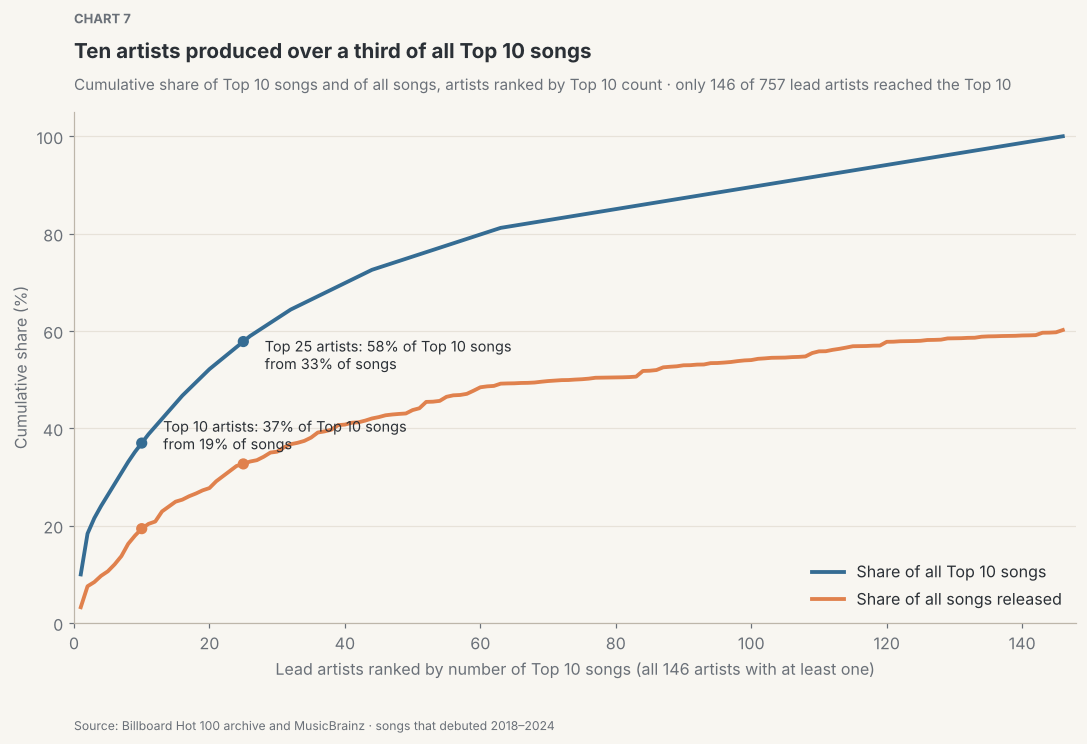

In [65]:
# Chart 7 — cumulative lines: artists ranked by Top 10 songs, adding up their share of hits and of all songs.
rank = concentration.index
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.plot(rank, cum_hits, color=FOCUS, linewidth=2.5, label="Share of all Top 10 songs")
ax.plot(rank, cum_songs, color=SECOND, linewidth=2.5, label="Share of all songs released")
for k, dy in [(10, -4), (25, -18)]:
    ax.scatter([k, k], [cum_hits.iloc[k - 1], cum_songs.iloc[k - 1]], color=[FOCUS, SECOND], s=40, zorder=3)
    ax.annotate(f"Top {k} artists: {cum_hits.iloc[k - 1]:.0f}% of Top 10 songs\nfrom {cum_songs.iloc[k - 1]:.0f}% of songs",
                (k, cum_hits.iloc[k - 1]), textcoords="offset points", xytext=(14, dy), fontsize=9.5)
ax.set(xlabel=f"Lead artists ranked by number of Top 10 songs (all {len(rank)} artists with at least one)",
       ylabel="Cumulative share (%)", xlim=(0, len(rank) + 2), ylim=(0, 105))
ax.grid(axis="y")
ax.legend(loc="lower right")
finish(fig, ax, 7, "Ten artists produced over a third of all Top 10 songs",
       f"Cumulative share of Top 10 songs and of all songs, artists ranked by Top 10 count · "
       f"only {len(rank)} of {songs_by_artist.size:,} lead artists reached the Top 10")

**Finding.** Only 146 of 757 lead artists reached the Top 10 at all. The top 10 artists produced 37.0% of all Top
10 songs from 19.4% of the songs, and the top 25 produced 57.8% from 32.7%. Drake (44) and Taylor Swift (37) alone
account for 18% of Top 10 songs.

**Interpretation.** Top 10 success is concentrated in a small group of artists who also release a lot of music,
which is why artist track record (Q2) is such a strong signal and why a few names can move any comparison. It also
explains a caution used throughout: results for small groups can be driven by one or two artists, as Q3b shows.

#### Q3a. Do songs by artists from outside the US reach the Top 10 more often than songs by US artists?

**Research question.** We compare the Top 10 rate of songs whose lead artist is from the US with songs whose lead
artist is from elsewhere, using the artist's country in MusicBrainz (4,222 training songs with a known country),
and then break the outside-US group down by country (countries with at least 40 songs).

**Hypothesis.** H₀: the Top 10 rate is the same for US and outside-US artists. H₁: it differs.

In [66]:
# Q3a test: lead artist's country (MusicBrainz), US vs outside the US, then by country (40+ songs).
artists = pd.read_csv("data/raw/mb_artists.csv").drop_duplicates("artist_mbid")[["artist_mbid", "country"]]
train["artist_mbid"] = train["artist_mbids"].str.split("|").str[0]                   # the lead artist's id
train = train.merge(artists, on="artist_mbid", how="left")
train["origin"] = np.where(train["country"] == "US", "US", "Outside the US")
train.loc[train["country"].isna(), "origin"] = np.nan                                # unknown country stays blank
print("training songs with no known artist country (left out):", train["origin"].isna().sum())
q3a = chi_square(train, "origin")
report(q3a, "Q3a: Top 10 rate, US vs outside the US")
big = train["country"].value_counts()
q3a_country = chi_square(train[train["country"].isin(big[big >= 40].index)], "country")
report(q3a_country, "Q3a: Top 10 rate by country (countries with 40+ songs)")

training songs with no known artist country (left out): 71
Q3a: Top 10 rate, US vs outside the US
--------------------------------------
  chi2(1) = 31.0   p = 2.63e-08   Cramer's V = 0.086 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
origin,,,
Outside the US,800,126,15.8
US,3422,309,9.0


Q3a: Top 10 rate by country (countries with 40+ songs)
------------------------------------------------------
  chi2(6) = 80.0   p = 3.58e-15   Cramer's V = 0.140 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
country,,,
CA,269,64,23.8
CO,44,2,4.5
GB,135,25,18.5
KR,73,12,16.4
MX,45,0,0.0
PR,121,9,7.4
US,3422,309,9.0


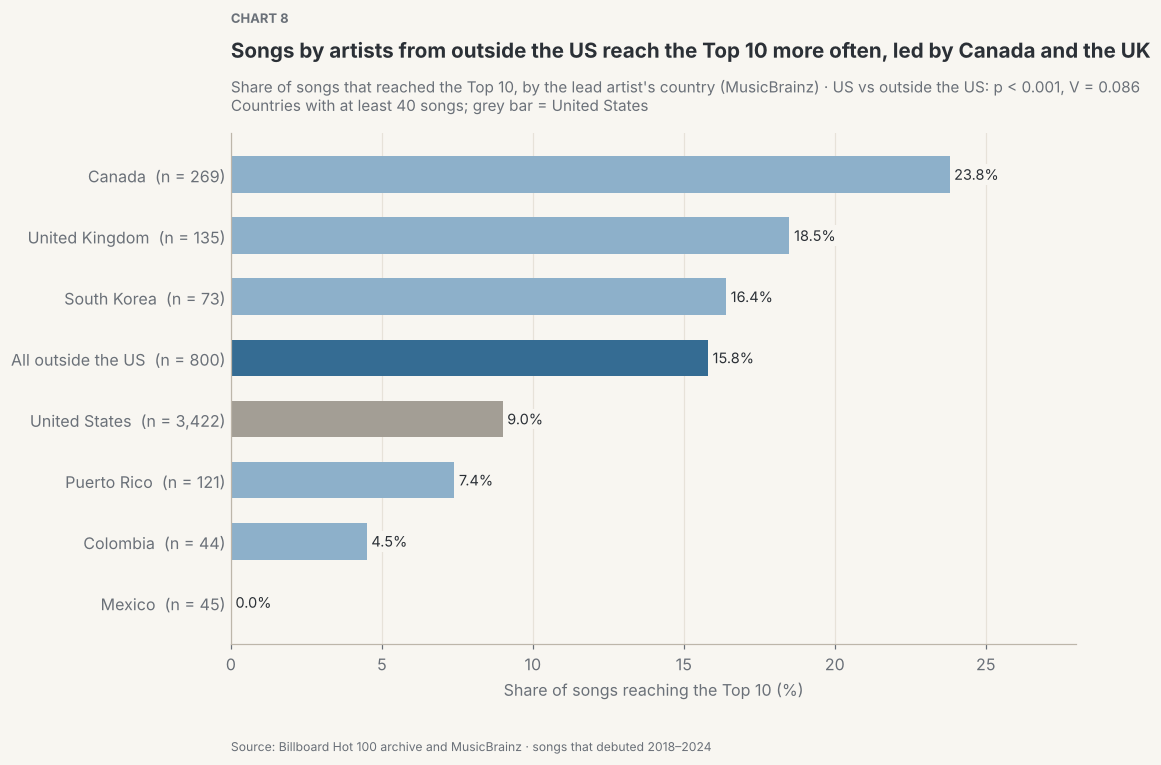

In [67]:
# Chart 8 — horizontal bars by country (40+ songs), plus the outside-US total and the US for reference.
data = pd.concat([q3a_country["summary"].drop(index="US"), q3a["summary"]]).sort_values("top10_rate_pct", ascending=False)
names = {"CA": "Canada", "GB": "United Kingdom", "KR": "South Korea", "PR": "Puerto Rico", "CO": "Colombia",
         "MX": "Mexico", "US": "United States", "Outside the US": "All outside the US"}
fig, ax = plt.subplots(figsize=(10, 5.8))
bars(ax, [f"{names[c]}  (n = {n:,})" for c, n in zip(data.index, data["songs"])],
     [("", data["top10_rate_pct"], [REF if c == "US" else FOCUS if c == "Outside the US" else FOCUS_LIGHT for c in data.index])],
     horizontal=True)
ax.set(xlabel=RATE_LABEL, xlim=(0, 28))
finish(fig, ax, 8, "Songs by artists from outside the US reach the Top 10 more often, led by Canada and the UK",
       f"Share of songs that reached the Top 10, by the lead artist's country (MusicBrainz) · "
       f"US vs outside the US: p < 0.001, V = {q3a['v']:.3f}\nCountries with at least 40 songs; grey bar = United States")

**Finding.** Songs by artists from outside the US reach the Top 10 at 15.8% (800 songs), against 9.0% for US artists
(3,422 songs), with χ²(1) = 31.0 and p < 0.001 (V = 0.086). By country, Canada leads at 23.8% (269 songs) and the
United Kingdom follows at 18.5% (135), while Puerto Rico (7.4%), Colombia (4.5%) and Mexico (0 of 45) sit below the US.

**Interpretation.** Artists who break into the US chart from abroad tend to be already-successful international stars,
so "outside the US" is not one group: English-speaking and K-pop acts convert well, Latin-market acts much less. The
overall effect is small (V = 0.086) but the country differences are larger (V = 0.140). Q3b checks whether track
record explains the gap; 71 songs whose lead artist has no country in MusicBrainz are left out.

#### Q3b. Does the origin gap hold among artists with a similar number of previous hits?

**Research question.** Within each previous-hit group (none, 1-4, 5-9, 10 or more), we compare the Top 10 rate of US
and outside-US artists. We also repeat the overall comparison without the three outside-US artists with the most Top
10 songs, to see how much a few stars drive the gap.

**Hypothesis.** H₀: within each previous-hit group, US and outside-US artists have the same Top 10 rate. H₁: the gap
remains.

In [68]:
# Q3b test: does the origin gap hold among artists with a similar number of previous Top 10s?
rows = {}
for group, g in train.groupby("prior_hit_group", observed=True):
    r = chi_square(g, "origin")
    s = r["summary"]
    rows[group] = {"n_us": s.loc["US", "songs"], "n_outside": s.loc["Outside the US", "songs"],
                   "rate_us": s.loc["US", "top10_rate_pct"], "rate_outside": s.loc["Outside the US", "top10_rate_pct"],
                   "p_value": round(r["p"], 4)}
q3b = pd.DataFrame.from_dict(rows, orient="index").rename_axis("previous_hits")
q3b["gap_pts"] = (q3b["rate_outside"] - q3b["rate_us"]).round(1)
display(q3b)

# How much do a few stars drive it? Repeat without the three outside-US artists with the most Top 10s.
outside = train[train["origin"] == "Outside the US"]
top3 = outside[outside["top10"]].groupby("primary_artist").size().sort_values(ascending=False).head(3)
print("Outside-US artists with the most Top 10 songs:", top3.to_dict())
print(f"share of outside-US Top 10 songs from these three: {top3.sum() / outside['top10'].sum():.1%}")
q3b_check = chi_square(train[~train["primary_artist"].isin(top3.index)], "origin")
report(q3b_check, "Q3b check: US vs outside the US, without those three artists")

,n_us,n_outside,rate_us,rate_outside,p_value,gap_pts
previous_hits,,,,,,
0,1189,292,5.6,6.8,0.4774,1.2
1-4,1194,212,8.0,14.6,0.0027,6.6
5-9,370,76,11.6,21.1,0.0429,9.5
10+,669,220,15.7,26.8,0.0003,11.1


Outside-US artists with the most Top 10 songs: {'Drake': 44, 'Bad Bunny': 9, 'The Weeknd': 8}
share of outside-US Top 10 songs from these three: 48.4%
Q3b check: US vs outside the US, without those three artists
------------------------------------------------------------
  chi2(1) = 4.1   p = 0.0426   Cramer's V = 0.032 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
origin,,,
Outside the US,548,65,11.9
US,3422,309,9.0


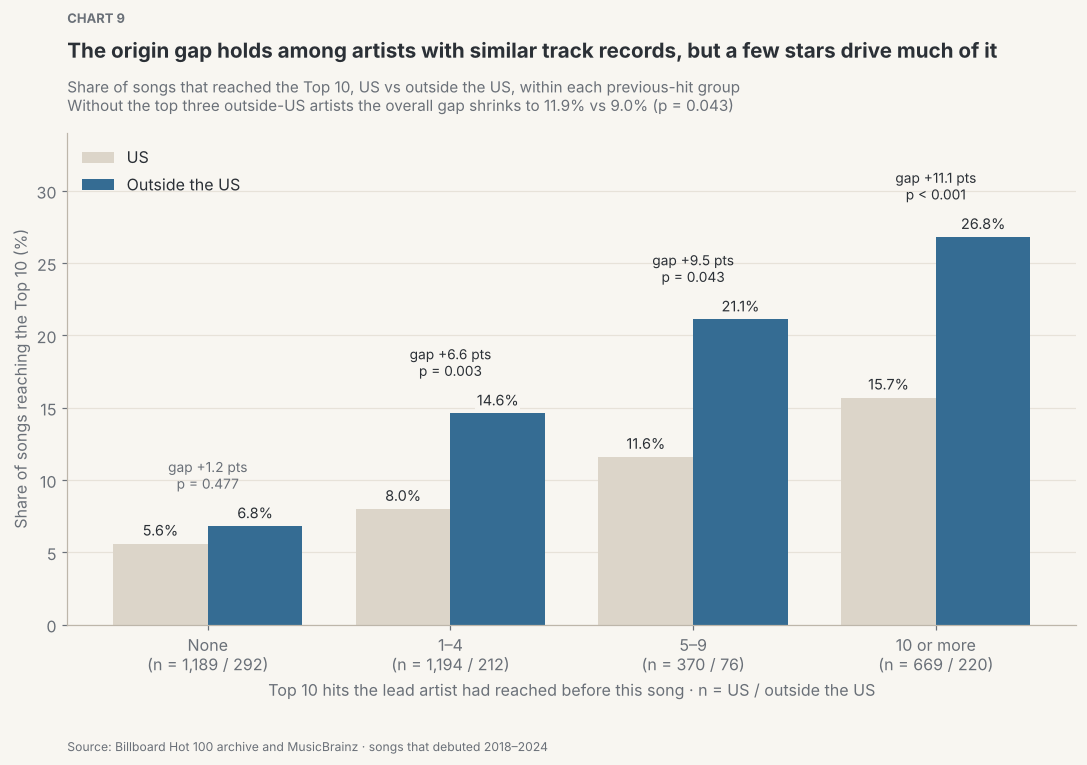

In [69]:
# Chart 9 — grouped bars: US vs outside the US within each previous-hit group, with gap and p-value.
fig, ax = plt.subplots(figsize=(10, 5.8))
bars(ax, [f"{g}\n(n = {a:,} / {b:,})" for g, a, b in zip(HIT_NAMES, q3b["n_us"], q3b["n_outside"])],
     [("US", q3b["rate_us"], CONTEXT), ("Outside the US", q3b["rate_outside"], FOCUS)])
for i, (gap, p, top) in enumerate(zip(q3b["gap_pts"], q3b["p_value"], q3b[["rate_us", "rate_outside"]].max(axis=1))):
    ax.text(i, top + 2.6, f"gap {gap:+.1f} pts\n" + ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"),
            ha="center", fontsize=9, color=TEXT if p < ALPHA else MUTED)
ax.set(xlabel="Top 10 hits the lead artist had reached before this song · n = US / outside the US", ylabel=RATE_LABEL, ylim=(0, 34))
ax.legend(loc="upper left")
s = q3b_check["summary"]["top10_rate_pct"]
finish(fig, ax, 9, "The origin gap holds among artists with similar track records, but a few stars drive much of it",
       "Share of songs that reached the Top 10, US vs outside the US, within each previous-hit group\n"
       f"Without the top three outside-US artists the overall gap shrinks to {s['Outside the US']:.1f}% vs {s['US']:.1f}% "
       f"(p = {q3b_check['p']:.3f})")

**Finding.** The gap holds in every group of artists with at least one previous hit: 14.6% vs 8.0% at 1-4 hits
(p = 0.003), 21.1% vs 11.6% at 5-9 (p = 0.043) and 26.8% vs 15.7% at 10 or more (p < 0.001). It does not appear among
artists with no previous hit (6.8% vs 5.6%, p = 0.48).

**Interpretation.** Track record alone does not explain the origin gap, but a few stars carry much of it: Drake, Bad
Bunny and The Weeknd produced 48% of outside-US Top 10 songs, and without them the overall gap shrinks to 11.9% vs 9.0%
(p = 0.043, a negligible effect). The safest reading is that established international stars convert unusually well on
the US chart, not that being from outside the US helps in general.

**Theme takeaway:** Top 10 songs are concentrated in a small set of artists (Q3). Outside-US artists convert better
than US artists (Q3a), and the gap survives controlling for previous hits, but it is carried largely by a handful of
international stars (Q3b).

### 4.4 Release strategy

Q4 looks at how many songs an artist debuts in the same week. Q4a checks whether the single format matters once that
is accounted for, and Q4b checks that the pattern holds in both of the largest genres.

#### Q4. Is the number of songs an artist debuts in the same week associated with Top 10 success?

**Research question.** We compare the Top 10 rate by how many songs the same lead artist debuted on the Hot
100 that week (1, 2-4, 5-9, 10 or more), overall and separately for artists with and without a previous Top
10. The variable counts chart debuts only, songs that actually entered the Hot 100, not every track on an
album; the first lines of the cell below recount it to confirm.

**Hypothesis.** H₀: the number of same-week debuts is unrelated to the Top 10 rate. H₁: it is associated
with it.

In [70]:
# Q4 check: the variable counts CHART DEBUTS (songs by the same lead artist that entered the Hot 100 in the
# same week), not every track on an album. Recount it from the data to confirm.
recount = df.groupby(["primary_artist", "first_chart_date"])["title"].transform("count")
print(f"recount matches same_artist_debuts_that_week for {(recount == df['same_artist_debuts_that_week']).mean():.1%} of songs")

# Q4 test: Top 10 rate by same-week debuts, overall and by artist history.
DEBUT_ORDER = ["1", "2-4", "5-9", "10+"]
q4 = chi_square(train, "album_debut_bucket")
report(q4, "Q4: Top 10 rate by same-week debuts by the same artist")
for group in ["No previous Top 10", "Previous Top 10"]:
    report(chi_square(train[train["artist_status"] == group], "album_debut_bucket"), f"Q4: {group}")

recount matches same_artist_debuts_that_week for 100.0% of songs
Q4: Top 10 rate by same-week debuts by the same artist
------------------------------------------------------
  chi2(3) = 44.5   p = 1.16e-09   Cramer's V = 0.102 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,2123,246,11.6
10+,1379,163,11.8
2-4,366,23,6.3
5-9,425,9,2.1


Q4: No previous Top 10
----------------------
  chi2(3) = 6.9   p = 0.0739   Cramer's V = 0.067 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,1129,75,6.6
10+,144,6,4.2
2-4,129,5,3.9
5-9,122,2,1.6


Q4: Previous Top 10
-------------------
  chi2(3) = 53.1   p = 1.77e-11   Cramer's V = 0.138 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,994,171,17.2
10+,1235,157,12.7
2-4,237,18,7.6
5-9,303,7,2.3


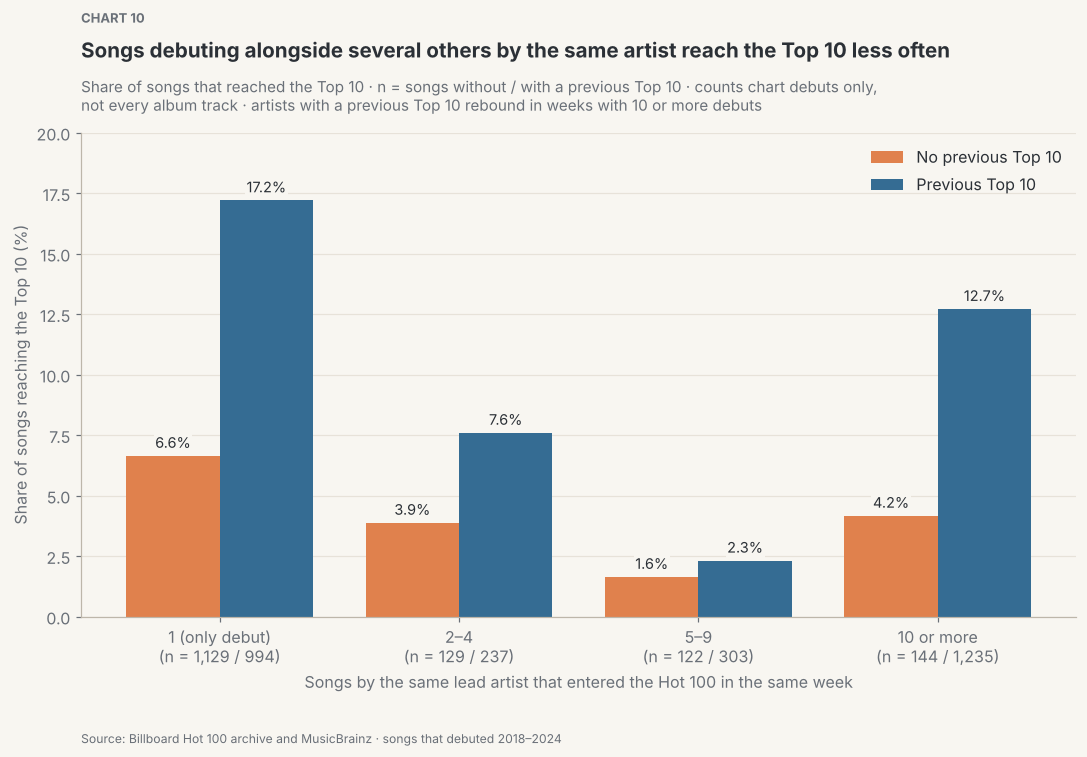

In [71]:
# Chart 10 — grouped bars by same-week debuts, artists without vs with a previous Top 10.
rates = train.pivot_table(index="album_debut_bucket", columns="artist_status", values="top10", aggfunc="mean").loc[DEBUT_ORDER] * 100
sizes = train.pivot_table(index="album_debut_bucket", columns="artist_status", values="top10", aggfunc="size").loc[DEBUT_ORDER]
fig, ax = plt.subplots(figsize=(10, 5.8))
bars(ax, [f"{g}\n(n = {a:,} / {b:,})" for g, a, b in zip(["1 (only debut)", "2–4", "5–9", "10 or more"],
                                                          sizes["No previous Top 10"], sizes["Previous Top 10"])],
     [("No previous Top 10", rates["No previous Top 10"], SECOND), ("Previous Top 10", rates["Previous Top 10"], FOCUS)])
ax.set(xlabel="Songs by the same lead artist that entered the Hot 100 in the same week", ylabel=RATE_LABEL, ylim=(0, 20))
finish(fig, ax, 10, "Songs debuting alongside several others by the same artist reach the Top 10 less often",
       "Share of songs that reached the Top 10 · n = songs without / with a previous Top 10 · counts chart debuts only,\n"
       "not every album track · artists with a previous Top 10 rebound in weeks with 10 or more debuts")

**Finding.** Songs that were the artist's only debut that week reach the Top 10 at 11.6%, against 6.3% with
2-4 same-week debuts and 2.1% with 5-9 (χ²(3) = 44.5, p < 0.001, V = 0.102). For artists with a previous Top
10 the pattern is clear (17.2%, 7.6%, 2.3%, then 12.7% at 10 or more, p < 0.001); for artists without one it
points the same way (6.6% down to 1.6%) but is not significant (p = 0.074).

**Interpretation.** More same-week debuts go with lower Top 10 rates up to 5-9 songs. The rebound at 10 or
more comes from established artists, whose very large releases still reach the Top 10 less often than their
solo debuts (12.7% vs 17.2%). This is an association: artists choose how many songs to release, and bigger
releases may differ in other ways. Because the variable counts only songs that charted, it measures how many
tracks broke onto the chart, not album size.

#### Q4a. Do singles and album tracks differ, and does any gap remain among songs debuting alone?

**Research question.** We compare the Top 10 rate of songs first released as singles, album tracks and EP
tracks (as listed by MusicBrainz), for all songs and then only for songs debuting alone. Most album tracks
debut alongside other songs, so Q4's pattern could explain an apparent singles advantage.

**Hypothesis.** H₀: among songs debuting alone, the rate is the same for singles, album tracks and EP tracks.
H₁: singles still differ.

In [72]:
# Q4a test: singles vs album tracks vs EP tracks, for all songs and then for songs debuting alone.
types = ["Single", "Album", "EP"]
typed = train[train["release_type"].isin(types)]
q4a_all = chi_square(typed, "release_type")
report(q4a_all, "Q4a: Top 10 rate by release type — ALL songs")
q4a_alone = chi_square(typed[typed["album_debut_bucket"] == "1"], "release_type")
report(q4a_alone, "Q4a: the same test — songs debuting ALONE")
for name, r in [("all songs", q4a_all), ("debuting alone", q4a_alone)]:
    rate = r["summary"]["top10_rate_pct"]
    print(f"single minus album track, {name}: {rate['Single'] - rate['Album']:+.1f} percentage points")

Q4a: Top 10 rate by release type — ALL songs
--------------------------------------------
  chi2(2) = 9.5   p = 0.00845   Cramer's V = 0.048 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
release_type,,,
Album,2528,232,9.2
EP,117,8,6.8
Single,1539,184,12.0


Q4a: the same test — songs debuting ALONE
-----------------------------------------
  chi2(2) = 3.1   p = 0.215   Cramer's V = 0.039 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
release_type,,,
Album,612,70,11.4
EP,75,4,5.3
Single,1387,166,12.0


single minus album track, all songs: +2.8 percentage points
single minus album track, debuting alone: +0.6 percentage points


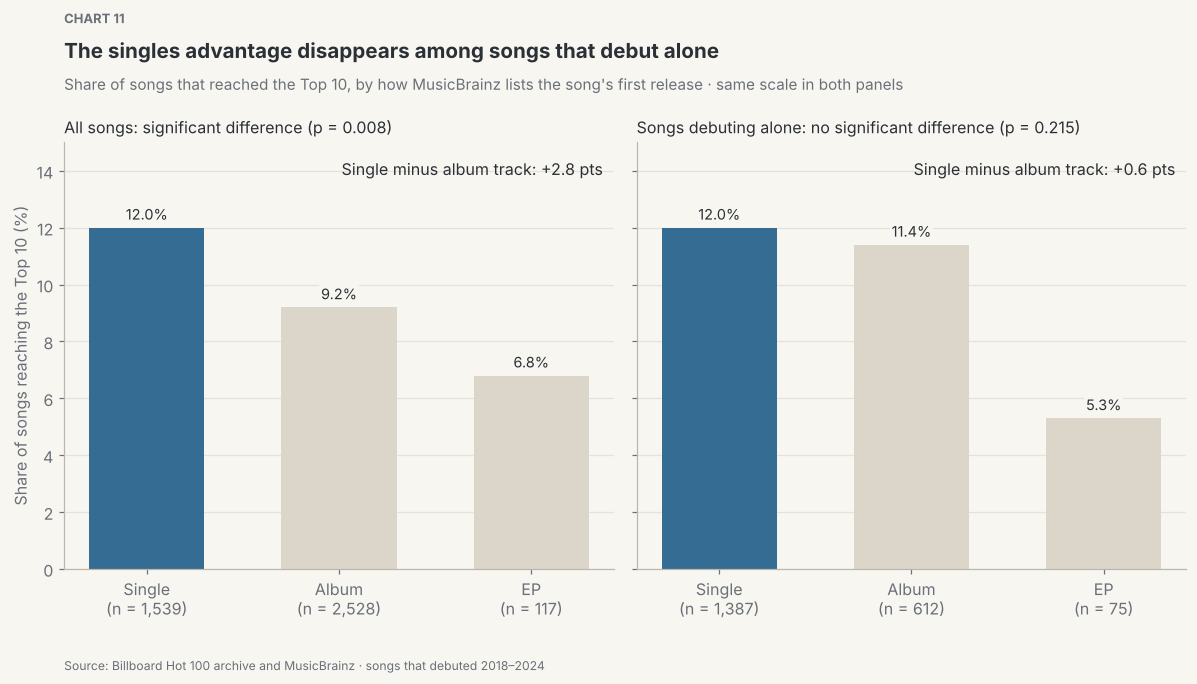

In [73]:
# Chart 11 — two panels on the same scale; each states the single minus album-track gap.
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
for ax, (name, result) in zip(axes, [("All songs", q4a_all), ("Songs debuting alone", q4a_alone)]):
    s = result["summary"].loc[types]
    bars(ax, [f"{t}\n(n = {n:,})" for t, n in zip(types, s["songs"])], [("", s["top10_rate_pct"], [FOCUS, CONTEXT, CONTEXT])])
    gap = s.loc["Single", "top10_rate_pct"] - s.loc["Album", "top10_rate_pct"]
    ax.text(0.98, 0.96, f"Single minus album track: {gap:+.1f} pts", transform=ax.transAxes, ha="right", va="top")
    verdict = "significant difference" if result["p"] < ALPHA else "no significant difference"
    ax.set_title(f"{name}: {verdict} (p = {result['p']:.3f})", fontsize=10.5, loc="left")
axes[0].set(ylabel=RATE_LABEL, ylim=(0, 15))
finish(fig, axes[0], 11, "The singles advantage disappears among songs that debut alone",
       "Share of songs that reached the Top 10, by how MusicBrainz lists the song's first release · same scale in both panels",
       extra_space=20)

**Finding.** Across all songs, singles reach the Top 10 2.8 points more often than album tracks (12.0% vs
9.2%, p = 0.008). Among songs debuting alone the gap shrinks to 0.6 points (12.0% vs 11.4%) and is not
significant (p = 0.215).

**Interpretation.** 90% of singles debut alone, against 24% of album tracks, so the overall singles advantage
largely reflects same-week debuts (Q4) rather than the single format itself. EP tracks are few (75 debuting
alone), and 109 songs with other release types are left out.

#### Q4b. Is the same-week debut pattern found in both hip-hop and pop?

**Research question.** We repeat Q4 separately for the two largest genres, hip-hop/rap (2,017 songs) and pop (796).
Hip-hop artists release far more multi-song weeks, so Q4's pattern could be a hip-hop habit rather than a general one.

**Hypothesis.** H₀: within each genre, the Top 10 rate is the same however many songs the artist debuts that week.
H₁: it differs.

In [74]:
# Q4b test: is the same-week debut pattern from Q4 found in both of the two largest genres?
q4b = {genre: chi_square(train[train["primary_genre"] == genre], "album_debut_bucket") for genre in ["hip-hop/rap", "pop"]}
for genre, result in q4b.items():
    report(result, f"Q4b: same-week debuts by the same artist — {genre}")

Q4b: same-week debuts by the same artist — hip-hop/rap
------------------------------------------------------
  chi2(3) = 32.5   p = 4.18e-07   Cramer's V = 0.127 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,679,74,10.9
10+,842,90,10.7
2-4,232,12,5.2
5-9,264,2,0.8


Q4b: same-week debuts by the same artist — pop
----------------------------------------------
  chi2(3) = 8.5   p = 0.0362   Cramer's V = 0.104 (small)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
album_debut_bucket,,,
1,497,103,20.7
10+,194,37,19.1
2-4,54,4,7.4
5-9,51,5,9.8


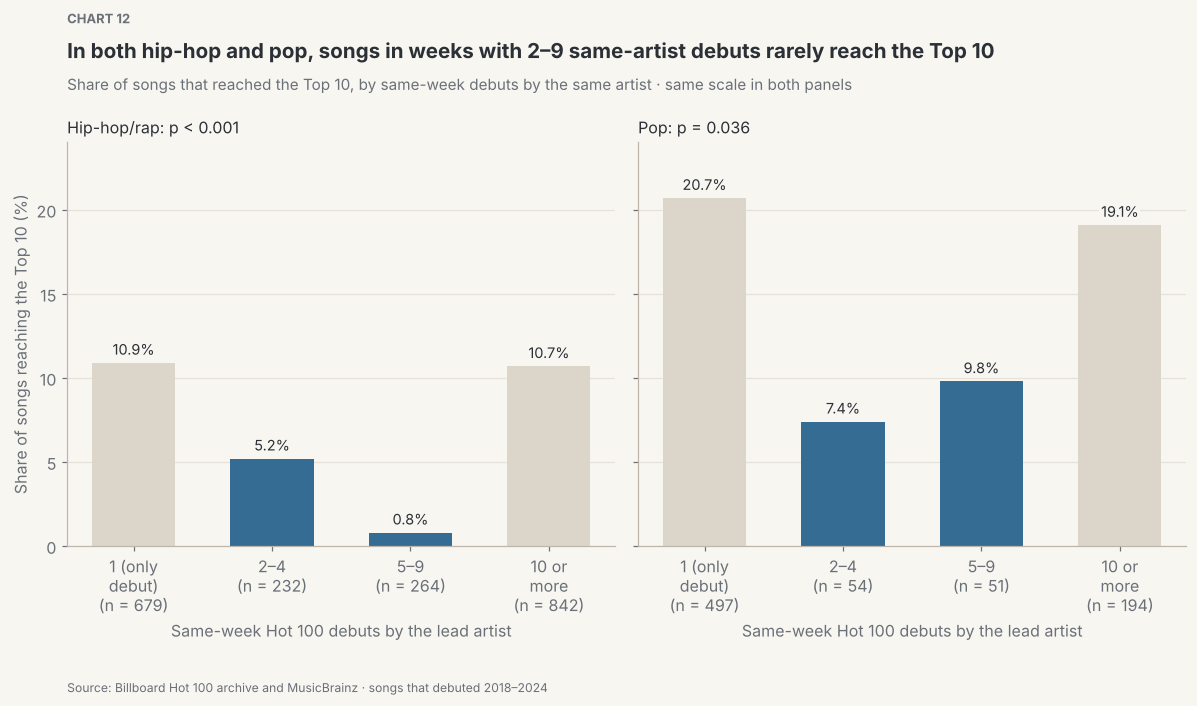

In [75]:
# Chart 12 — two panels on the same scale, hip-hop and pop; the 2-4 and 5-9 groups highlighted.
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
for ax, (genre, result) in zip(axes, q4b.items()):
    s = result["summary"].loc[DEBUT_ORDER]
    bars(ax, [f"{g}\n(n = {n:,})" for g, n in zip(["1 (only\ndebut)", "2–4", "5–9", "10 or\nmore"], s["songs"])],
         [("", s["top10_rate_pct"], [CONTEXT, FOCUS, FOCUS, CONTEXT])])
    ax.set_title(f"{GENRE_NAMES[genre]}: " + ("p < 0.001" if result["p"] < 0.001 else f"p = {result['p']:.3f}"), fontsize=10.5, loc="left")
    ax.set_xlabel("Same-week Hot 100 debuts by the lead artist")
axes[0].set(ylabel=RATE_LABEL, ylim=(0, 24))
finish(fig, axes[0], 12, "In both hip-hop and pop, songs in weeks with 2–9 same-artist debuts rarely reach the Top 10",
       "Share of songs that reached the Top 10, by same-week debuts by the same artist · same scale in both panels",
       extra_space=20)

**Finding.** The pattern appears in both genres. In hip-hop, the rate falls from 10.9% for songs debuting alone to 5.2%
with 2-4 same-week debuts and 0.8% with 5-9 (p < 0.001, V = 0.127). In pop it falls from 20.7% to 7.4% and 9.8%
(p = 0.036, V = 0.104).

**Interpretation.** Weeks with 2-9 same-artist debuts go with much lower Top 10 rates in both genres, so Q4 is not just
a hip-hop effect. In both genres the rate recovers for 10 or more debuts (10.7% and 19.1%), the superstar album weeks
seen in Q4. Pop's middle groups are small (54 and 51 songs), so their exact rates are uncertain.

**Theme takeaway:** debuting alongside several of the artist's other songs goes with lower Top 10 rates (Q4), in both
hip-hop and pop (Q4b). The singles advantage largely disappears among songs debuting alone (Q4a).

### 4.5 Timing and lyrics

Q5 tests the chart debut month, and Q5a asks how the genre make-up of Top 10 songs changed over time. Q5b tests the
lyrics, the factor the project started out expecting to matter.

#### Q5. Does the Top 10 rate differ by chart debut month, and does any difference survive excluding big same-artist debut weeks?

**Research question.** We compare the Top 10 rate across the twelve months of the song's chart debut (the week it
first entered the Hot 100, not its release date). We then repeat the test without songs that debuted in a week
when their artist placed five or more songs on the chart at once, because superstar releases cluster in a few
months.

**Hypothesis.** H₀: the debut month is unrelated to the Top 10 rate. H₁: some months have higher rates.

In [76]:
# Q5 test: Top 10 rate by CHART DEBUT month (from first_chart_date, not the release date).
# Second test: drop songs that debuted in a week when their artist placed 5+ songs on the chart at once.
q5_all = chi_square(train, "debut_month")
report(q5_all, "Q5: Top 10 rate by chart debut month — ALL songs")
no_bomb = train[train["album_debut_bucket"].isin(["1", "2-4"])]
print(f"songs left after excluding 5+ same-artist debut weeks: {len(no_bomb):,} of {len(train):,}")
q5_nb = chi_square(no_bomb, "debut_month")
report(q5_nb, "Q5: the same test, EXCLUDING songs from 5+ same-artist debut weeks")

Q5: Top 10 rate by chart debut month — ALL songs
------------------------------------------------
  chi2(11) = 25.0   p = 0.00915   Cramer's V = 0.076 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_month,,,
1,288,26,9.0
2,300,26,8.7
3,355,25,7.0
4,361,39,10.8
5,392,59,15.1
6,370,36,9.7
7,414,36,8.7
8,360,34,9.4
9,352,34,9.7


songs left after excluding 5+ same-artist debut weeks: 2,489 of 4,293
Q5: the same test, EXCLUDING songs from 5+ same-artist debut weeks
------------------------------------------------------------------
  chi2(11) = 5.5   p = 0.906   Cramer's V = 0.047 (negligible)
  -> cannot reject the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_month,,,
1,213,22,10.3
2,224,22,9.8
3,213,19,8.9
4,221,25,11.3
5,189,27,14.3
6,235,28,11.9
7,215,20,9.3
8,226,26,11.5
9,185,17,9.2


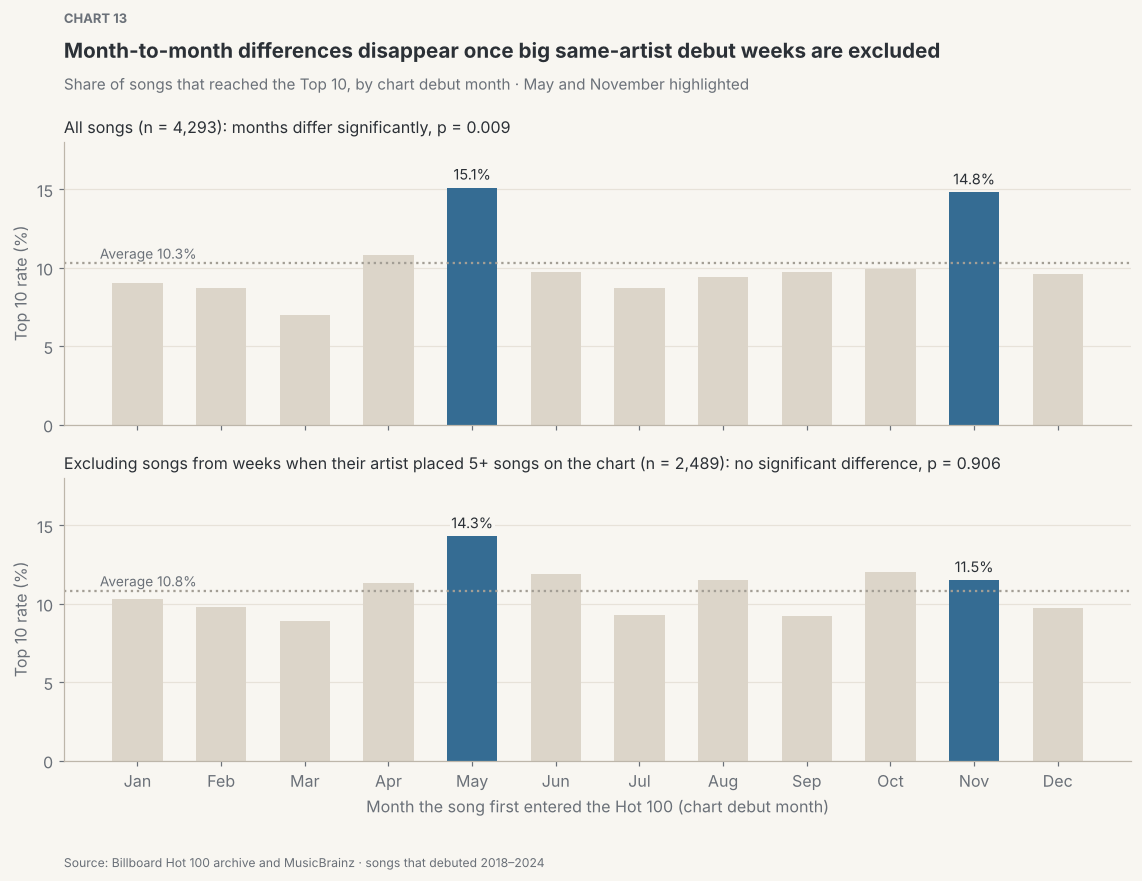

In [77]:
# Chart 13 — two panels on the same scale, all songs vs excluding 5+ debut weeks; May and November highlighted.
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True, sharey=True)
for ax, (name, result, data) in zip(axes, [("All songs", q5_all, train),
                                           ("Excluding songs from weeks when their artist placed 5+ songs on the chart", q5_nb, no_bomb)]):
    rate, avg = result["summary"]["top10_rate_pct"], data["top10"].mean() * 100
    bars(ax, months, [("", rate, [FOCUS if m in (5, 11) else CONTEXT for m in rate.index])],
         bar_labels=[f"{v:.1f}%" if m in (5, 11) else "" for m, v in rate.items()])
    ax.axhline(avg, color=REF, linestyle=":")
    ax.text(-0.45, avg + 0.3, f"Average {avg:.1f}%", fontsize=9, color=MUTED)
    verdict = "months differ significantly" if result["p"] < ALPHA else "no significant difference"
    ax.set_title(f"{name} (n = {len(data):,}): {verdict}, p = {result['p']:.3f}", fontsize=10.5, loc="left")
    ax.set(ylabel="Top 10 rate (%)", ylim=(0, 18), yticks=range(0, 16, 5))
axes[1].set_xlabel("Month the song first entered the Hot 100 (chart debut month)")
finish(fig, axes[0], 13, "Month-to-month differences disappear once big same-artist debut weeks are excluded",
       "Share of songs that reached the Top 10, by chart debut month · May and November highlighted", extra_space=20)

**Finding.** Across all songs, the Top 10 rate varies by chart debut month (p = 0.009), peaking in May (15.1%) and
November (14.8%) against 10.3% overall. After excluding the 1,804 songs from weeks when their artist placed five or
more songs on the chart, the differences are not significant (p = 0.906).

**Interpretation.** The apparent release season mostly reflects a few very large same-artist debut weeks. May stays
high after filtering (14.3%), but with 189 songs and a non-significant overall test it is consistent with chance.
The filter also removes 42% of songs, so part of the change in p-value is lost statistical power.

#### Q5a. How did the genre make-up of Top 10 songs change, and did any genre's own Top 10 rate change?

**Research question.** Two related comparisons across 2018-20, 2021-22 and 2023-24: (1) the share of each genre among
Top 10 songs (panel A), and (2) the Top 10 rate within each main genre (panel B). A genre's share of hits can rise
because more of its songs chart or because its songs convert better, so we test both.

**Hypothesis.** H₀: the genre make-up of Top 10 songs is the same in all three periods, and each genre's Top 10 rate
is constant. H₁: they changed.

In [78]:
# Q5a test: (1) has the genre MIX of Top 10 songs changed across three periods? (2) has each genre's
# Top 10 RATE changed? These are different questions, so they get different tests.
main = ["hip-hop/rap", "pop", "country", "R&B"]
train["period"] = pd.cut(train["debut_year"], [2017, 2020, 2022, 2024], labels=["2018–20", "2021–22", "2023–24"])
train["genre_group"] = np.where(train["primary_genre"].isin(main), train["primary_genre"], "other genres")
hits = train[train["top10"]]
mix = pd.crosstab(hits["period"], hits["genre_group"])[main + ["other genres"]]
mix_chi2, mix_p, mix_dof, _ = stats.chi2_contingency(mix)
print(f"(1) genre mix of Top 10 songs by period: chi2({mix_dof}) = {mix_chi2:.1f}   p = {mix_p:.3g}   "
      f"-> {'REJECT the null' if mix_p < ALPHA else 'cannot reject the null'} at alpha = {ALPHA}")
share = (mix.div(mix.sum(axis=1), axis=0) * 100).round(1)
display(share.assign(top10_songs=mix.sum(axis=1)))

print("(2) Top 10 rate by period within each main genre:")
rows = {}
for genre in main:
    r = chi_square(train[train["primary_genre"] == genre], "period")
    rows[genre] = {**r["summary"]["top10_rate_pct"].to_dict(), "p_value": round(r["p"], 3)}
rate_by_period = pd.DataFrame.from_dict(rows, orient="index")
display(rate_by_period)
print("Each main genre's share of ALL debuts (not just Top 10 songs), by period (%):")
display(pd.crosstab(train["period"], train["genre_group"], normalize="index").mul(100).round(1)[main])

(1) genre mix of Top 10 songs by period: chi2(8) = 18.7   p = 0.0167   -> REJECT the null at alpha = 0.05


genre_group,hip-hop/rap,pop,country,R&B,other genres,top10_songs
period,,,,,,
2018–20,44.4,37.8,2.2,3.9,11.7,180
2021–22,39.3,29.3,6.4,10.0,15.0,140
2023–24,35.5,33.1,11.6,7.4,12.4,121


(2) Top 10 rate by period within each main genre:


,2018–20,2021–22,2023–24,p_value
hip-hop/rap,8.7,9.3,8.5,0.863
pop,19.7,18.6,17.3,0.770
country,2.4,6.2,7.0,0.124
R&B,5.8,9.8,15.8,0.098


Each main genre's share of ALL debuts (not just Top 10 songs), by period (%):


genre_group,hip-hop/rap,pop,country,R&B
period,,,,
2018–20,51.5,19.3,9.3,6.8
2021–22,46.2,17.2,11.3,11.2
2023–24,41.3,18.8,16.3,4.6


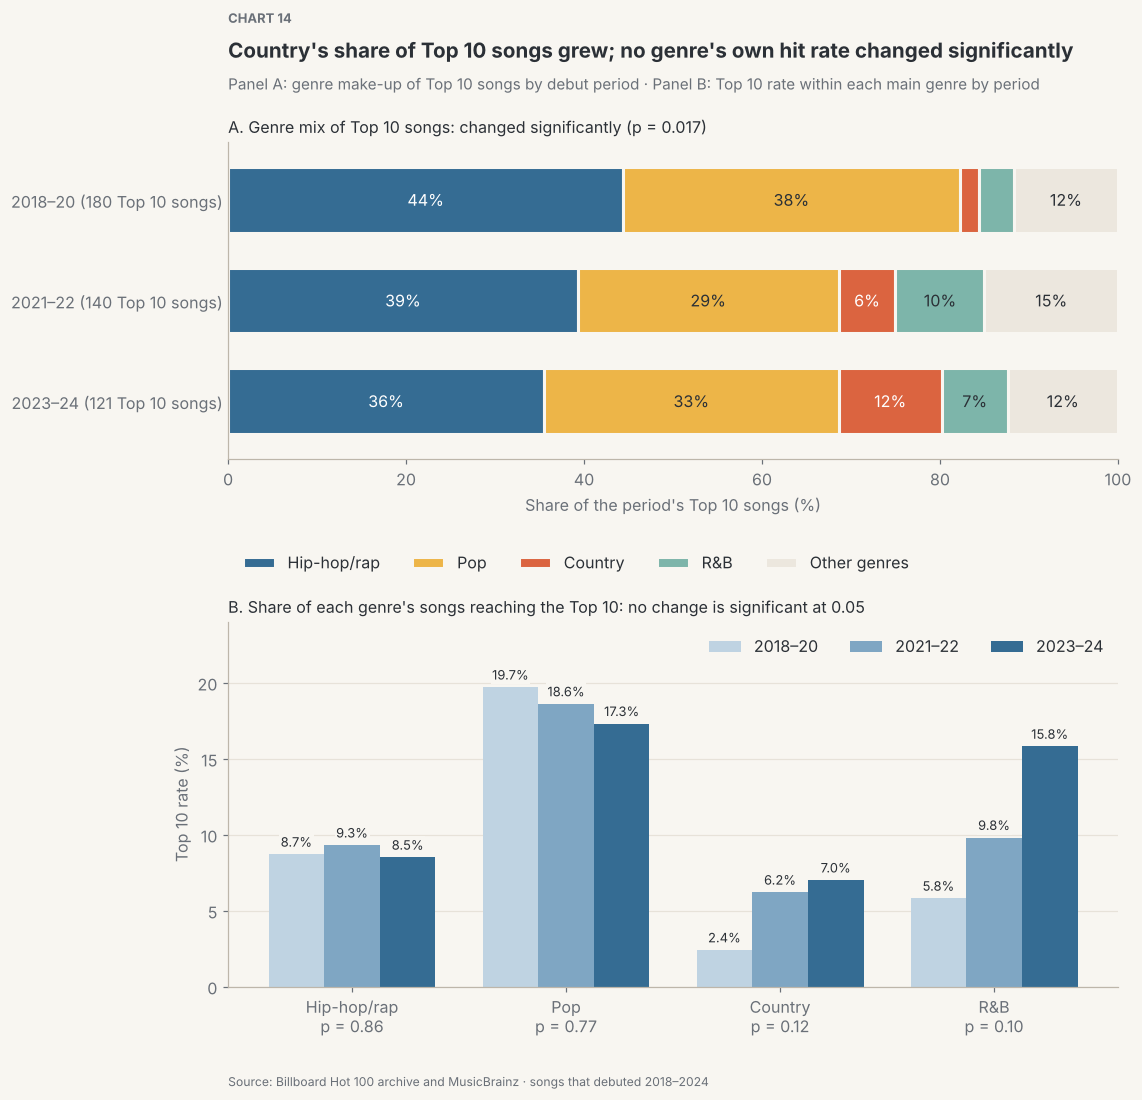

In [79]:
# Chart 14 — panel A: genre mix of Top 10 songs (100% stacked); panel B: each genre's Top 10 rate by period.
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(10.5, 9), gridspec_kw={"height_ratios": [1, 1.15]})
share.iloc[::-1].rename(columns=lambda c: GENRE_NAMES.get(c, "Other genres")).plot(
    kind="barh", stacked=True, color=[FOCUS, GOLD, CORAL, SEAFOAM, PALE], width=0.65, edgecolor=BACKGROUND, linewidth=2, ax=ax_a)
for drawn, genre in zip(ax_a.containers, share.columns):
    ax_a.bar_label(drawn, labels=[f"{v:.0f}%" if v >= 6 else "" for v in share[genre].iloc[::-1]], label_type="center",
                   color="white" if genre in ("hip-hop/rap", "country") else TEXT)
ax_a.set_yticks(range(3), [f"{p} ({n} Top 10 songs)" for p, n in mix.sum(axis=1).iloc[::-1].items()])
ax_a.set(xlabel="Share of the period's Top 10 songs (%)", ylabel="", xlim=(0, 100))
ax_a.tick_params(axis="y", length=0)
ax_a.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.25))
ax_a.set_title(f"A. Genre mix of Top 10 songs: changed significantly (p = {mix_p:.3f})", fontsize=10.5, loc="left")

periods = ["2018–20", "2021–22", "2023–24"]
bars(ax_b, [f"{GENRE_NAMES[g]}\np = {p:.2f}" for g, p in rate_by_period["p_value"].items()],
     [(period, rate_by_period[period], colour) for period, colour in zip(periods, ["#BFD3E2", "#7FA6C3", FOCUS])])
ax_b.set(ylabel="Top 10 rate (%)", ylim=(0, 24))
ax_b.legend(ncol=3, loc="upper right")
ax_b.set_title("B. Share of each genre's songs reaching the Top 10: no change is significant at 0.05", fontsize=10.5, loc="left")
finish(fig, ax_a, 14, "Country's share of Top 10 songs grew; no genre's own hit rate changed significantly",
       "Panel A: genre make-up of Top 10 songs by debut period · Panel B: Top 10 rate within each main genre by period",
       extra_space=20)

**Finding.** The genre make-up of Top 10 songs changed (p = 0.017): country's share rose from 2.2% to 11.6% and hip-hop's
fell from 44.4% to 35.5%, while pop stayed near a third. No main genre's own Top 10 rate changed significantly (country
2.4% to 7.0%, p = 0.12; R&B 5.8% to 15.8%, p = 0.10).

**Interpretation.** Country's growing share of hits comes at least partly from more country songs charting (9.3% to
16.3% of all debuts); its higher hit rate points the same way but is not significant. For modelling, the genre mix of
the 2025-26 test songs may differ from training. Each period has only 121-180 Top 10 songs.

#### Q5b. Do Top 10 songs differ from other songs on four lyric measures?

**Research question.** We compare Top 10 songs with songs that peaked at 11-100 on word count, unique-word
ratio, repetition score and words per line (4,274 training songs with lyrics).

Unique-word ratio, explained: the lyric "baby baby baby oh" has 4 words but only 2 different ones, so its ratio
is 2 ÷ 4 = 0.5. Repetition score is the share of lines that appear more than once.

**Hypothesis.** H₀: each measure is distributed the same way in both groups. H₁: they differ; the "catchiness"
idea predicts hits are more repetitive with a smaller vocabulary.

In [80]:
# Q5b test: compare four lyric measures between Top 10 songs and the rest (songs with lyrics only).
lyric_cols = ["word_count", "unique_word_ratio", "repetition_score", "avg_line_length"]
q5b = pd.DataFrame({col: mann_whitney(train, col) for col in lyric_cols}).T.rename_axis("feature")
q5b["difference"] = q5b["median_top10"] - q5b["median_other"]
q5b["significant"] = np.where(q5b["p"] < ALPHA, "yes", "no")
print(f"Mann-Whitney U, n = {q5b['n_top10'].iloc[0]:.0f} Top 10 vs {q5b['n_other'].iloc[0]:,.0f} others (songs with lyrics only)")
print("effect_r: rank-biserial correlation; under 0.1 in size is negligible\n")
display(q5b[["median_top10", "median_other", "difference", "effect_r", "p", "significant"]].round(3)
        .assign(p=q5b["p"].map(lambda p: float(f"{p:.3g}"))))

Mann-Whitney U, n = 439 Top 10 vs 3,835 others (songs with lyrics only)
effect_r: rank-biserial correlation; under 0.1 in size is negligible



,median_top10,median_other,difference,effect_r,p,significant
feature,,,,,,
word_count,433.000,422.000,11.000,0.052,0.073400,no
unique_word_ratio,0.348,0.361,-0.012,-0.113,0.000097,yes
repetition_score,0.418,0.407,0.011,0.041,0.162000,no
avg_line_length,7.850,7.860,-0.010,-0.041,0.155000,no


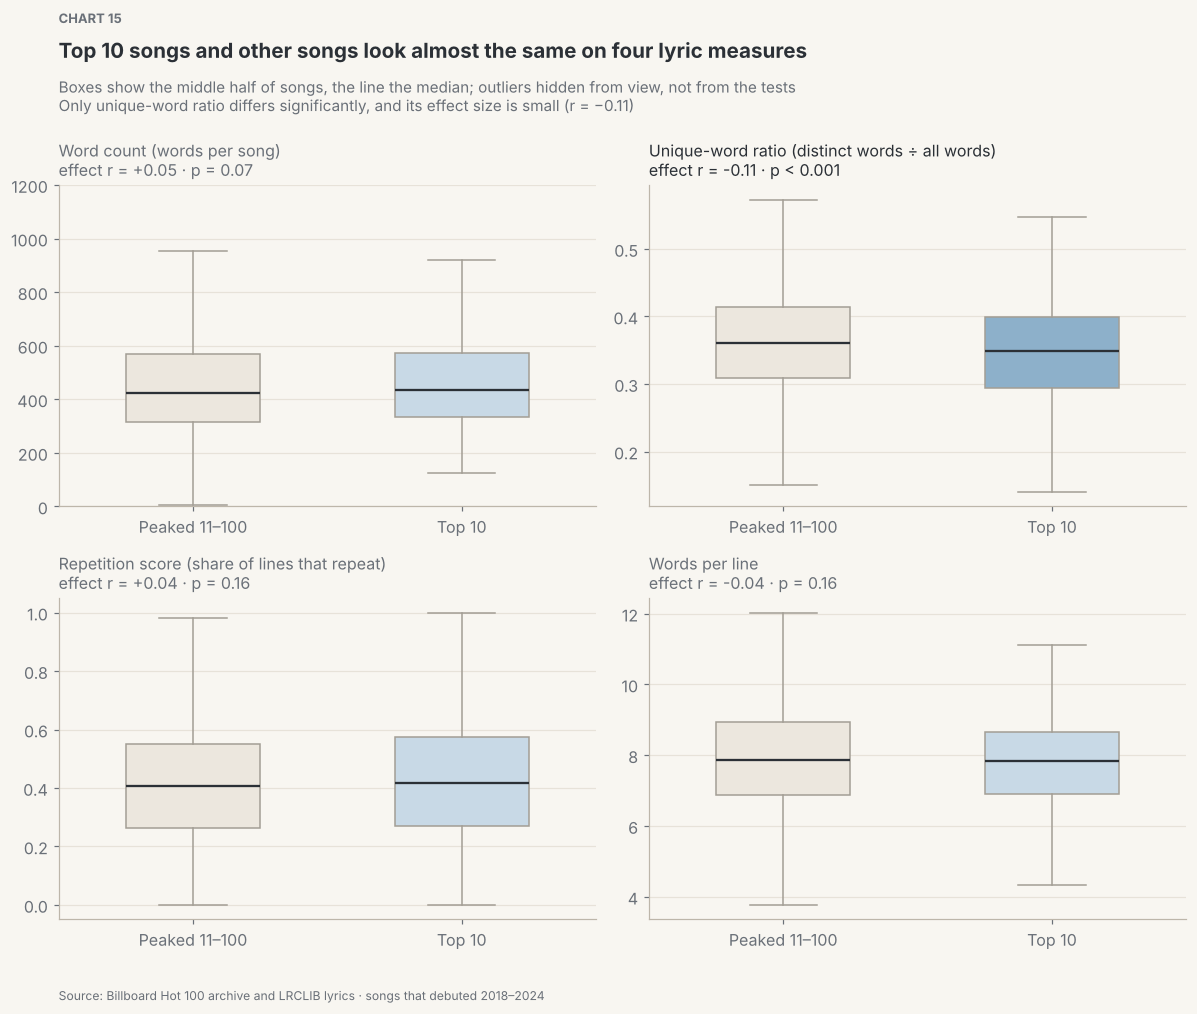

In [81]:
# Chart 15 — four box plots (2 x 2), Top 10 vs the rest. Outliers are hidden from view only, not from the tests.
titles = {"word_count": "Word count (words per song)", "unique_word_ratio": "Unique-word ratio (distinct words ÷ all words)",
          "repetition_score": "Repetition score (share of lines that repeat)", "avg_line_length": "Words per line"}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, lyric_cols):
    p, r = q5b.loc[col, "p"], q5b.loc[col, "effect_r"]
    parts = ax.boxplot([train.loc[~train["top10"], col].dropna(), train.loc[train["top10"], col].dropna()],
                       tick_labels=["Peaked 11–100", "Top 10"], patch_artist=True, widths=0.5, showfliers=False,
                       medianprops=dict(color=TEXT, linewidth=1.5), boxprops=dict(color=REF),
                       whiskerprops=dict(color=REF), capprops=dict(color=REF))
    for box, colour in zip(parts["boxes"], [PALE, FOCUS_LIGHT if p < ALPHA else FOCUS_PALE]):
        box.set_facecolor(colour)
    ax.set_title(f"{titles[col]}\neffect r = {r:+.2f} · " + ("p < 0.001" if p < 0.001 else f"p = {p:.2f}"),
                 fontsize=10.5, loc="left", color=TEXT if p < ALPHA else MUTED)
    ax.grid(axis="y")
axes[0, 0].set_ylim(0, 1200)
finish(fig, axes[0, 0], 15, "Top 10 songs and other songs look almost the same on four lyric measures",
       "Boxes show the middle half of songs, the line the median; outliers hidden from view, not from the tests\n"
       "Only unique-word ratio differs significantly, and its effect size is small (r = −0.11)",
       source="Source: Billboard Hot 100 archive and LRCLIB lyrics · songs that debuted 2018–2024", extra_space=34)

**Finding.** Only unique-word ratio differs significantly: Top 10 songs have a median of 0.348 against 0.361 (p < 0.001),
a small effect (r = -0.11). Word count (p = 0.07), repetition (p = 0.16) and words per line (p = 0.16) do not differ.

**Interpretation.** Lyric form carries little signal about chart success, which answers the lyric part of our research
question. Even the one difference mostly reflects genre: inside each of the four largest genres the unique-word gap is
negligible (r between -0.07 and -0.10) and not significant, while pop, the most successful genre, simply uses the fewest
distinct words. These measures count words without reading them, so topic and sentiment remain untested. The 19 training
songs without lyrics are left out rather than scored 0.

**Theme takeaway:** the month pattern disappears once big same-artist debut weeks are removed (Q5). What did change over
time is the genre make-up of hits, mainly because more country songs reached the chart (Q5a). Lyrics barely distinguish
Top 10 songs (Q5b).

### 4.6 Methodology note: does debut position predict the final peak, or is the question circular?

**Hypothesis.** H₀: debut position is unrelated to reaching the Top 10. H₁: a strong debut predicts a strong peak.

This is not one of the 15 questions. We include it because it is a trap, and falling into it is instructive.

In [82]:
# Method note, naive version: Top 10 rate by debut position (this shows the leakage problem).
print("The naive answer\n" + "-" * 44)
naive = train.copy()
naive["debut_bucket"] = pd.cut(naive["debut_position"], [0, 10, 25, 50, 75, 100],
                               labels=["1-10", "11-25", "26-50", "51-75", "76-100"])
display(
    naive.groupby("debut_bucket", observed=True)
         .agg(songs=("title", "size"), top10=("top10", "sum"))
         .assign(top10_rate_pct=lambda t: (t["top10"] / t["songs"] * 100).round(1))
)

debuted_inside = train[train["debut_position"] <= 10]
print(f"\nSongs debuting at positions 1-10: {len(debuted_inside)}")
print(f"  of which reached the Top 10: {debuted_inside['top10'].sum()} "
      f"({debuted_inside['top10'].mean()*100:.0f}%)")
print("  ^ this is a DEFINITION, not a finding: 'top10' means the song ever")
print("    held a position in 1-10, so debuting there already satisfies it.")

The naive answer
--------------------------------------------


,songs,top10,top10_rate_pct
debut_bucket,,,
1-10,303,303,100.0
11-25,435,29,6.7
26-50,775,37,4.8
51-75,1098,28,2.6
76-100,1682,44,2.6



Songs debuting at positions 1-10: 303
  of which reached the Top 10: 303 (100%)
  ^ this is a DEFINITION, not a finding: 'top10' means the song ever
    held a position in 1-10, so debuting there already satisfies it.


In [83]:
# Method note, honest version: only songs that debuted outside the Top 10.
print("The honest answer — songs that debuted at 11 or below\n" + "-" * 54)
outside = train[train["debut_position"] > 10].copy()
outside["debut_bucket"] = pd.cut(outside["debut_position"], [10, 25, 50, 75, 100],
                                 labels=["11-25", "26-50", "51-75", "76-100"])
debut_test = chi_square(outside, "debut_bucket")
report(debut_test, "Method note: climbing into the Top 10 from outside it")

The honest answer — songs that debuted at 11 or below
------------------------------------------------------
Method note: climbing into the Top 10 from outside it
-----------------------------------------------------
  chi2(3) = 23.7   p = 2.86e-05   Cramer's V = 0.077 (negligible)
  -> REJECT the null at alpha = 0.05



,songs,top10,top10_rate_pct
debut_bucket,,,
11-25,435,29,6.7
26-50,775,37,4.8
51-75,1098,28,2.6
76-100,1682,44,2.6


**Finding.** Debuting in the Top 10 makes a song a Top 10 song by definition, so we only count songs that climbed in; starting higher helps, but only a little.

**Interpretation.** The naive table shows a 100% Top 10 rate for songs debuting at
positions 1-10, which looks like the strongest predictor in the study and is in fact
pure target leakage: `top10` is defined as ever occupying positions 1-10, so a song
debuting there has already met the definition. Any model given `debut_position` would
score superbly and have learned nothing.

Excluding those 303 songs gives the real answer. Among songs debuting at 11 or below,
climbing into the Top 10 still depends on where they start — 6.7% from 11-25 down to
2.6% from 76-100 (p ≈ 2.9×10⁻⁵) — but the effect is small (V = 0.077), far weaker
than prior artist success.

**Caveat.** The leak here is obvious once seen. The general lesson is that a feature
recorded during the outcome window needs checking against the target's *definition*, not
just its timing, and that a suspiciously excellent predictor deserves suspicion first.

### 4.7 What the 15 questions add up to

- Eleven find a clear association that holds up: genre (Q1, Q1a), previous hits and hit ratio (Q2, Q2a, Q2b), concentration (Q3), origin (Q3a, Q3b), same-week debuts (Q4, Q4b) and the change in the genre make-up of hits (Q5a).
- One holds in part: the previous-hit gap is significant in three of five large genres (Q1b).
- Three show that an apparent pattern is explained by something else: the singles advantage (Q4a) and the release season (Q5) both reflect same-week debuts, and lyric form barely separates hits (Q5b).

#### Tested and dropped

These were tested on the same training songs and found no clear difference, so they are not part of the main analysis.

| What we tested | Result |
|---|---|
| Featured artist on the credit, compared within lead-artist history | 9.6% vs 10.4%; no significant difference within either group (p = 0.12 and 0.43) |
| Result of the artist's previous release, within prior-hit groups | Significant only for artists with 1-4 hits (13.3% vs 8.0%, p = 0.017); not for 5-9 or 10+ |
| Unique-word ratio within each genre | Negligible and not significant in all four large genres (summarised in Q5b) |
| Lyrics containing profanity | 10.1% vs 10.5% overall (p = 0.71); one significant genre, country, rests on 8 hits in 40 songs |
| Time from release to chart debut | Small overall gap (V = 0.057) that disappears within artists with and without a previous hit |

**So what:** who releases a song and how it is released are associated with far more of the difference than anything in
the song's lyrics. Every result is an association; checking each pattern against a likely confounder kept misleading
findings out of our conclusions.

## 5. Conclusion

### 5.1 Prioritised insights

Ranked by expected impact against the effort to act on them.

| # | Insight | Evidence | Impact | Feasibility | Verdict |
|---|---|---|---|---|---|
| 1 | Same-week debuts are the strongest release-related association. A song that is the artist's only debut that week reaches the Top 10 at 11.6%; with 5-9 same-week debuts, 2.1%, in both hip-hop and pop. The "single" label shows no association once this is accounted for | Q4 (p < 0.001, V = 0.102), Q4a, Q4b | High: a 5x difference | High: release scheduling is a decision | Worth testing. Spacing out releases is a candidate lever, but only an experiment or a model with artist controls can show it causes higher placement |
| 2 | Artist track record shows the clearest gradients, and it is not actionable. 18.5% for 10+ previous Top 10s vs 5.8% for none; hit ratio is at least as telling; a first-time entrant does far better than a long-time charter without a hit | Q2 (V = 0.158), Q2a (V = 0.166), Q2b | High: about a 3-4x difference | Low: cannot be changed for a given artist | Use for forecasting, not strategy. Test hit count and hit ratio as model features |
| 3 | Top 10 success is concentrated, and established international stars convert unusually well. Ten artists produced 37% of Top 10 songs; outside-US artists 15.8% vs 9.0% | Q3, Q3a, Q3b | Medium: concentration means a few names drive results | Low: cannot be changed | Check every result for single-artist influence, and treat origin as a weak, star-driven signal |
| 4 | Genre shifts the odds about 3.5x, and the make-up of hits is moving. Pop 18.7%, country 5.3%; the gap remains among songs debuting alone; country's share of hits grew, mainly through more country songs charting | Q1 (p < 0.001), Q1a, Q1b, Q5a | Medium: real but V = 0.146 | Low: an artist cannot switch genre on request | Use as a baseline adjustment, and check whether genre effects shift in the 2025-26 test years |
| 5 | Lyric form carries almost no signal, and two apparent patterns were artefacts. The release season and the singles advantage both reflect same-week debuts; debut position meets the target's definition; previous hits had to be recounted to use only information known at debut | Q5b, Q5, Q4a, 4.0c, 4.6 | High: each would have shipped a wrong claim | High: costs one extra check each | Do not invest further in surface lyric measures. Re-test any effect that could be explained by who released the song or how, and check every feature's timing |

### 5.2 Risks and limitations

Data and licensing. The Billboard archive repository declares no licence, and
LRCLIB publishes none on its public docs page; only MusicBrainz is explicitly CC0. Chart
compilations and lyrics are both copyrighted. This work is non-commercial academic
analysis and the raw lyrics should not be redistributed.

Coverage that is not random. 166 songs (3.1%) have no genre, and coverage is worst
for 2026 (93.7%) because recent releases are less tagged — so the most recent year is
also the least complete. 54 songs are missing MusicBrainz data entirely, mostly
initialism titles ("B.I.T.C.H.", "1.5") that defeat the search. Missingness correlates
with title style, which is not random.

Measurement. Genre comes from volunteer tagging, not a taxonomy. 96 songs are
`mixed` because two genres tied. The profanity flag is a keyword list. 109 songs carry
`lyrics_suspect_short` and their lyric features may understate the real text.

Design. The target is a threshold on a continuous outcome: a song peaking at 11 is
counted with one peaking at 100. Nine years is nine observations of any yearly trend.
Same-week debut count is confounded with artist size and we cannot fully separate them; Q3a, Q4a
and Q5a show how often that kind of confound changes the answer.
And crucially, everything here is association, not causation — nothing was randomised.

What would change our conclusions. If playlist and marketing-spend data were
available, we would expect much of the "artist history" effect to be absorbed by them,
since those are the mechanism rather than the cause.

### 5.3 Next steps

1. Fit a baseline model on the 2018-2024 training split (logistic regression with previous Top 10s counted at debut,
   hit ratio, genre and same-week debut bucket) and evaluate it once on the held-out 2025-2026 songs. Report precision
   and recall at a useful threshold, not accuracy: a model that always predicts "no" is 90% accurate and worthless.
2. Compare models with hit count alone, hit ratio alone and both (Q2, Q2a), and test whether pop's smaller history gap
   (Q1b) holds up with a genre-by-history interaction.
3. Check how much a few artists drive each result (Q3, Q3b), for example by refitting without the top five artists.
4. Let the genre effect change over time, since Q5a shows the make-up of hits is shifting, and check whether the model's
   genre weights still fit 2025-2026.
5. Test lyric content, not lyric form: sentiment and topic features, since Q5b rules out the surface measures rather than
   lyrics as a whole.
6. Separate artist size from release strategy using artist fixed effects, which would turn Q4 from an association into
   something closer to a recommendation.

**So what:** the most actionable association is about how a song is released; the clearest gradient is about who
released it; and the lyric hypothesis that motivated the project does not survive contact with the data.

## 6. References

Data sources

1. Hollingshead, M. *Billboard Hot 100 archive* — JSON files for every Billboard Hot 100
   chart, 1958-2026. https://github.com/mhollingshead/billboard-hot-100 (accessed
   September 2026). No licence declared by the repository.
2. *LRCLIB* — open lyrics database and API. https://lrclib.net/docs (accessed September
   2026). No licence stated on the public documentation page.
3. *MusicBrainz* — open music encyclopedia; recordings, release groups and artists.
   https://musicbrainz.org/doc/MusicBrainz_API (accessed September 2026). Core data
   released under CC0; see https://musicbrainz.org/doc/About/Data_License.

Software

4. McKinney, W. (2010). Data structures for statistical computing in Python. *pandas*.
5. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature* 585, 357-362.
6. Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific
   computing in Python. *Nature Methods* 17, 261-272.
7. Hunter, J. D. (2007). Matplotlib: a 2D graphics environment. *Computing in Science &
   Engineering* 9(3), 90-95.
   Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source
   Software* 6(60), 3021.
8. Bachmann, M. *RapidFuzz* — fast fuzzy string matching.
   https://github.com/rapidfuzz/RapidFuzz (used in the collection scripts).

Method

9. Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
   (Cramér's V, used throughout as the effect size alongside chi-square.)
10. Mann, H. B. & Whitney, D. R. (1947). On a test of whether one of two random variables
    is stochastically larger than the other. *Annals of Mathematical Statistics* 18(1),
    50-60.
11. Kerby, D. S. (2014). The simple difference formula: an approach to teaching nonparametric
    correlation. *Comprehensive Psychology* 3. (Rank-biserial r, the effect size for Mann-Whitney.)

Project code. Collection and cleaning scripts are in `scripts/` (`01_billboard.py`
through `08_features.py`); every column in the analysis file is documented in
`docs/data_dictionary.md`.

**So what:** every number in this notebook traces to a documented source or a script in
this repository, so any claim here can be checked rather than taken on trust.

## 7. AI usage disclosure

Our team used Claude as the primary AI assistant for this project. Through the Claude Code extension in VS Code, we used it to draft and debug Python code for data cleaning, explain statistical functions, and refine written descriptions in this Colab notebook. All AI-generated code and text were independently reviewed by our team. We tested each script, corrected logical errors, and modified the code as needed to ensure that it accurately reflected our data and intended analysis. We also revised AI-assisted explanations to match our own interpretation of the results. To verify the statistical results, we independently recalculated key metrics directly from the raw source data and compared those values with the outputs, tables, and charts produced in the notebook. We then checked that our written interpretations and conclusions were consistent with these verified results.
